In [ ]:
URL_RE     = re.compile(r"https?://\S+|www\.\S+")
EMAIL_RE   = re.compile(r"\S+@\S+\.\S+")
MENTION_RE = re.compile(r"@\w+")
HTML_RE    = re.compile(r"<[^>]+>|&[a-z]+;")
RUN_RE     = re.compile(r"(.)\1{%d,}" % MAX_CHAR_RUN)
WS_RE      = re.compile(r"\s+")
BANGLA_RE  = re.compile(r"[ঀ-৿]")
EMOJI_RE   = re.compile("[" "\U0001F000-\U0001FAFF" "☀-➿" "←-⇿" "⬀-⯿" "️" "❤" "]")
INVISIBLE  = {0x200B: None, 0xFEFF: None, 0x00AD: None, 0x2060: None}
BANGLA_DIGITS = str.maketrans("০১২৩৪৫৬৭৮৯", "0123456789")

def clean_text(text: str) -> str:
    t = unicodedata.normalize("NFC", str(text))
    t = URL_RE.sub(" ", t); t = EMAIL_RE.sub(" ", t)
    t = HTML_RE.sub(" ", t); t = MENTION_RE.sub(" ", t)
    t = t.replace("#", " ")
    t = t.translate(INVISIBLE)
    if UNIFY_BANGLA_DIGITS: t = t.translate(BANGLA_DIGITS)
    if not KEEP_EMOJI:      t = EMOJI_RE.sub(" ", t)
    t = RUN_RE.sub(r"\1" * MAX_CHAR_RUN, t)
    return WS_RE.sub(" ", t).strip()

need_nfc = raw[TEXT_COL].astype(str).map(
    lambda t: unicodedata.normalize("NFC", t) != t).mean()
print(f"rows needing NFC normalisation: {need_nfc*100:.1f}%")

df = raw.copy()
df["text_clean"] = df[TEXT_COL].map(clean_text)
words = df["text_clean"].str.split().str.len().fillna(0)
print(f"emptied by cleaning : {(df['text_clean'].str.len()==0).sum():,}")
print(f"under {MIN_WORDS} word         : {(words<MIN_WORDS).sum():,}")
df = df[(df["text_clean"].str.len() > 0) & (words >= MIN_WORDS)].reset_index(drop=True)
print(f"no Bangla script    : {(~df['text_clean'].str.contains(BANGLA_RE)).sum():,} (kept)")
print(f"\n{len(raw):,} -> {len(df):,} rows")
df[[TEXT_COL, "text_clean"]].head(3)

rows needing NFC normalisation: 55.0%
emptied by cleaning : 0
under 1 word         : 0
no Bangla script    : 1 (kept)

80,000 -> 80,000 rows


,Sentence,text_clean
0,কি হল আজকাল বাংলাদেশে। নাস্তিক মুরতাত এত বেরেই...,কি হল আজকাল বাংলাদেশে। নাস্তিক মুরতাত এত বেরেই...
1,জবাই করা লাগে,জবাই করা লাগে
2,খালেদার স্বাস্থ্য পরীক্ষার জন্য বিএসএমএমইউ গেল...,খালেদার স্বাস্থ্য পরীক্ষার জন্য বিএসএমএমইউ গেল...


In [ ]:
n_orig, n_clean = df[TEXT_COL].nunique(), df["text_clean"].nunique()
conf = df.groupby("text_clean")[LABEL_COL].nunique()
print(f"unique raw sentences    : {n_orig:,}")
print(f"unique cleaned sentences: {n_clean:,}")
print(f"collapsed by cleaning   : {n_orig-n_clean:,}  <-- would leak if grouped on raw text")
print(f"label conflicts         : {int((conf>1).sum()):,} groups -> majority vote")

per = (df.groupby(["text_clean", LABEL_COL], sort=False)
         .agg(n=(LABEL_COL, "size"), c=("confidence", "max")).reset_index()
         .sort_values(["text_clean", "n", "c"], ascending=[True, False, False]))
winner = per.drop_duplicates("text_clean", keep="first")[["text_clean", LABEL_COL]]

cand = df.merge(winner, on=["text_clean", LABEL_COL], how="inner").copy()
cand["_meta"] = cand[STRATA].notna().all(axis=1).astype(int)
cand = cand.sort_values(["_meta", "confidence"], ascending=[False, False])
df = cand.drop_duplicates("text_clean", keep="first").drop(columns="_meta").reset_index(drop=True)
print(f"\n-> {len(df):,} unique rows")
print(df[LABEL_COL].value_counts().to_string())

unique raw sentences    : 58,825
unique cleaned sentences: 58,119
collapsed by cleaning   : 706  <-- would leak if grouped on raw text
label conflicts         : 54 groups -> majority vote

-> 58,119 unique rows
label
not bully    19240
troll        16565
sexual       11655
religious     8276
threat        2383


In [ ]:
def water_fill(caps: dict, total: int) -> dict:
    """Max-min fair allocation of `total` across classes, respecting per-class caps."""
    if total > sum(caps.values()):
        raise ValueError(f"target {total:,} exceeds capacity {sum(caps.values()):,}")
    alloc, remaining, pool = {}, total, dict(caps)
    while pool:
        level  = remaining // len(pool)
        pinned = [c for c, cap in pool.items() if cap <= level]
        if not pinned:
            for c in pool: alloc[c] = level
            left = remaining - level * len(pool)
            for c in sorted(pool, key=lambda k: pool[k], reverse=True):
                if left <= 0: break
                if alloc[c] < pool[c]: alloc[c] += 1; left -= 1
            break
        for c in pinned:
            alloc[c] = pool[c]; remaining -= pool[c]; del pool[c]
    return alloc

def _quota(sizes: pd.Series, target: int) -> dict:
    """Proportional strata allocation summing to exactly `target`."""
    s = {k: int(v) for k, v in sizes.items()}; tot = sum(s.values())
    exact = {k: v / tot * target for k, v in s.items()}
    q = {k: int(np.floor(v)) for k, v in exact.items()}
    left = target - sum(q.values())
    order = sorted(s, key=lambda k: exact[k] - q[k], reverse=True)
    while left > 0:
        placed = False
        for k in order:
            if left <= 0: break
            if q[k] < s[k]: q[k] += 1; left -= 1; placed = True
        if not placed: break
    return q

df["resample_origin"] = "original"
df["_stratum"] = (df[STRATA[0]].fillna("<missing>").astype(str) + "|"
                  + df[STRATA[1]].fillna("<missing>").astype(str))
uniq  = df[LABEL_COL].value_counts()
caps  = {k: int(np.floor(MAX_OVERSAMPLE * v)) for k, v in uniq.items()}
alloc = water_fill(caps, TOTAL_TARGET)

blocks = []
for lab in uniq.index:
    blk, tgt, n = df[df[LABEL_COL] == lab], alloc[lab], uniq[lab]
    if n > tgt:                                    # stratified undersample
        q = _quota(blk.groupby("_stratum", observed=True).size(), tgt)
        blk = pd.concat([g.sample(n=q.get(k, 0), random_state=rng)
                         for k, g in blk.groupby("_stratum", observed=True)
                         if q.get(k, 0) > 0], ignore_index=True)
        note = "undersampled"
    elif n < tgt:                                  # even-repetition oversample
        whole, rem = divmod(tgt, n)
        parts = [blk] * whole
        if rem: parts.append(blk.sample(n=rem, replace=False, random_state=rng))
        blk = pd.concat(parts, ignore_index=True)
        blk.loc[n:, "resample_origin"] = "oversampled_copy"
        note = "pinned at 2x cap" if tgt == caps[lab] else "oversampled"
    else:
        note = "unchanged"
    print(f"  {lab:<12}{n:>7,} -> {tgt:>6,}  ({tgt/n:.2f}x)  {note}")
    blocks.append(blk)

bal = pd.concat(blocks, ignore_index=True).drop(columns="_stratum")
c = bal[LABEL_COL].value_counts()
print(f"\ntotal {len(bal):,} rows | imbalance {c.max()/c.min():.2f}:1")

  not bully    19,240 -> 19,561  (1.02x)  oversampled
  troll        16,565 -> 19,561  (1.18x)  oversampled
  sexual       11,655 -> 19,560  (1.68x)  oversampled
  religious     8,276 -> 16,552  (2.00x)  pinned at 2x cap
  threat        2,383 ->  4,766  (2.00x)  pinned at 2x cap

total 80,000 rows | imbalance 4.10:1


In [ ]:
classes     = sorted(bal[LABEL_COL].unique())
label_to_id = {c: i for i, c in enumerate(classes)}
bal["label_id"] = bal[LABEL_COL].map(label_to_id).astype("int64")
mapping = {"label_to_id": label_to_id,
           "id_to_label": {str(i): c for c, i in label_to_id.items()},
           "classes_in_id_order": classes, "num_classes": len(classes)}
for c_ in classes: print(f"  {c_:<12} -> {label_to_id[c_]}")

  not bully    -> 0
  religious    -> 1
  sexual       -> 2
  threat       -> 3
  troll        -> 4


In [ ]:
def stratified_assign(strat_keys: pd.Series, seed: int = SEED) -> pd.Series:
    """Assign each group to train/val/test, stratified within every cell."""
    rs, names = np.random.RandomState(seed), ("train", "val", "test")
    fracs = np.array([TRAIN, VAL, TEST], dtype=float)
    out = pd.Series(index=strat_keys.index, dtype=object)
    for _, sub in strat_keys.groupby(strat_keys, sort=True):
        idx = sub.index.to_numpy(); rs.shuffle(idx); n = len(idx)
        exact  = n * fracs
        counts = np.floor(exact).astype(int)
        for j in np.argsort(-(exact - counts))[: n - int(counts.sum())]:
            counts[j] += 1                          # largest-remainder rounding
        pos = 0
        for name, cnt in zip(names, counts):
            out[idx[pos:pos + cnt]] = name; pos += cnt
    return out

g = bal.groupby("text_clean").agg(label=(LABEL_COL, "first"), n=("text_clean", "size"))
g["skey"] = g["label"] + "__n" + g["n"].astype(str)
freq = g["skey"].value_counts(); thin = set(freq[freq < 4].index)
if thin:
    g.loc[g["skey"].isin(thin), "skey"] = g.loc[g["skey"].isin(thin), "label"]
print(f"comment groups {len(g):,} | rows {len(bal):,} | cells {g['skey'].nunique()}")

bal["split"] = bal["text_clean"].map(stratified_assign(g["skey"]))
parts = {k: bal[bal["split"] == k].sample(frac=1.0, random_state=rng).reset_index(drop=True)
         for k in ("train", "val", "test")}
train, val, test = parts["train"], parts["val"], parts["test"]

for k, p in parts.items():
    print(f"  {k:<6}{len(p):>7,} rows ({len(p)/len(bal)*100:5.2f}%)  "
          f"{p['text_clean'].nunique():>6,} groups  "
          f"{int((p['resample_origin']=='oversampled_copy').sum()):>6,} copies")
print()
print(pd.DataFrame({k: p[LABEL_COL].value_counts(normalize=True).mul(100).round(2)
                    for k, p in parts.items()}).to_string())

comment groups 58,119 | rows 80,000 | cells 8
  train  55,998 rows (70.00%)  40,682 groups  15,316 copies
  val    12,005 rows (15.01%)   8,721 groups   3,284 copies
  test   11,997 rows (15.00%)   8,716 groups   3,281 copies

           train    val   test
label                         
not bully  24.45  24.44  24.46
religious  20.69  20.69  20.69
sexual     24.45  24.45  24.46
threat      5.96   5.96   5.95
troll      24.45  24.46  24.45


In [ ]:
cnt, k_ = train[LABEL_COL].value_counts(), len(classes)
class_weights = {lab: len(train) / (k_ * cnt[lab]) for lab in classes}
weights_payload = {"by_label": class_weights,
                   "by_id": {str(label_to_id[l]): v for l, v in class_weights.items()},
                   "note": "n/(k*count), computed on train only"}
for lab in classes:
    print(f"  {lab:<12} n={cnt[lab]:>7,}  weight={class_weights[lab]:.4f}")

# Keras: model.fit(..., class_weight=class_weight_by_id)
# Torch: nn.CrossEntropyLoss(weight=torch.tensor([...], dtype=torch.float))
class_weight_by_id = {int(label_to_id[l]): float(v) for l, v in class_weights.items()}
print("\nkeras/torch ready:", {k: round(v, 4) for k, v in class_weight_by_id.items()})

  not bully    n= 13,693  weight=0.8179
  religious    n= 11,586  weight=0.9666
  sexual       n= 13,691  weight=0.8180
  threat       n=  3,336  weight=3.3572
  troll        n= 13,692  weight=0.8180

keras/torch ready: {0: 0.8179, 1: 0.9666, 2: 0.818, 3: 3.3572, 4: 0.818}


Word2vec

In [ ]:
# ===================== CELL 9A (NEW — place ABOVE Cell 9) =====================
from gensim.models import Word2Vec, FastText

EMB_ALGO        = "word2vec"     # "word2vec" | "fasttext"  <-- the ONLY arm switch
USE_EXTRA_TEXT  = True           # +24,786 leak-free unlabelled sentences

EMB_DIM         = 200            # sweep 100/150/200 — same value in BOTH arms
W2V_MIN_COUNT   = 1              # sweep 1/2/3
W2V_WINDOW      = 8              # sweep 5/8/10
W2V_SG          = 1              # skip-gram: better on small corpora
W2V_NEG         = 10             # sweep 5/10/15
W2V_SAMPLE      = 1e-4           # sweep 1e-3/1e-4
W2V_NS_EXP      = 0.75           # sweep 0.75/0.5
W2V_EPOCHS      = 40             # sweep 20/40/60 — 960K tokens needs many passes
FT_MIN_N, FT_MAX_N = 2, 5        # FastText only; no Word2Vec analogue

# ---- corpus: train text + text dropped during balancing, never val/test -------
train_docs      = train["text_clean"].drop_duplicates().tolist()
emb_corpus_docs = list(train_docs)

if USE_EXTRA_TEXT:
    _src = pd.read_csv(SRC, encoding="utf-8")
    _src["text_clean"] = _src[TEXT_COL].map(clean_text)     # same clean_text as Cell 3
    _held = set(val["text_clean"]) | set(test["text_clean"])
    _seen = set(train_docs)
    for t in _src["text_clean"]:
        if t and t not in _seen and t not in _held:
            _seen.add(t); emb_corpus_docs.append(t)

assert not (set(emb_corpus_docs) & set(val["text_clean"])),  "LEAK: val text in corpus"
assert not (set(emb_corpus_docs) & set(test["text_clean"])), "LEAK: test text in corpus"

corpus = [t.split() for t in emb_corpus_docs]
print(f"corpus {len(corpus):,} docs | {sum(map(len, corpus)):,} tokens  [leak-free]")

# ---- train ------------------------------------------------------------------
_kw = dict(sentences=corpus, vector_size=EMB_DIM, window=W2V_WINDOW,
           min_count=W2V_MIN_COUNT, sg=W2V_SG, negative=W2V_NEG,
           ns_exponent=W2V_NS_EXP, sample=W2V_SAMPLE, epochs=W2V_EPOCHS,
           workers=1, seed=SEED)          # workers=1 or runs are NOT reproducible
if EMB_ALGO == "fasttext":
    _kw.update(min_n=FT_MIN_N, max_n=FT_MAX_N)

emb_model = (FastText if EMB_ALGO == "fasttext" else Word2Vec)(**_kw)
kv = emb_model.wv

def get_vec(word):
    """Word2Vec raises KeyError on OOV; FastText composes from subwords.
       `word in kv` is False for OOV even when kv[word] works — never use `in`."""
    try:
        return kv[word]
    except KeyError:
        return None

print(f"{EMB_ALGO}: {len(kv):,} trained vectors | dim {kv.vector_size}")

corpus 40,682 docs | 645,620 tokens  [leak-free]
word2vec: 85,796 trained vectors | dim 200


In [ ]:
# ============================ CELL 9 (REPLACE) ================================
import zlib

N_UNK_BUCKETS  = 64                          # hashed OOV buckets, not one <unk>
INCLUDE_UNSEEN = (EMB_ALGO == "fasttext")    # only FastText can fill those rows

corpus_counts = Counter(w for s in corpus for w in s)
core = [w for w, c in corpus_counts.most_common() if c >= W2V_MIN_COUNT]

vocab = {"<pad>": 0}
vocab.update({f"<unk{b}>": 1 + b for b in range(N_UNK_BUCKETS)})
OFF = len(vocab)
vocab.update({w: OFF + i for i, w in enumerate(core)})
N_CORE = len(vocab)

if INCLUDE_UNSEEN:
    # Words absent from the corpus but present in the data. Their vectors are
    # composed by a model fitted on the corpus alone, so no label or
    # co-occurrence information from val/test enters — this is inference-time
    # composition, precomputed. Set INCLUDE_UNSEEN=False for the strict variant.
    _seen, extra = set(vocab), []
    for part in (train, val, test):
        for t in part["text_clean"]:
            for w in str(t).split():
                if w not in _seen:
                    _seen.add(w)
                    if get_vec(w) is not None:      # only if FastText can compose it
                        extra.append(w)
    vocab.update({w: N_CORE + i for i, w in enumerate(extra)})

def unk_id(w):
    """zlib.crc32 is stable across processes; Python's hash() is salted and is NOT."""
    return 1 + (zlib.crc32(w.encode("utf-8")) % N_UNK_BUCKETS)

MAXLEN = int(train["text_clean"].str.split().str.len().quantile(0.95))

def encode_sequences(texts, maxlen=MAXLEN):
    out = np.zeros((len(texts), maxlen), dtype="int32")
    for i, t in enumerate(texts):
        ids = [vocab[w] if w in vocab else unk_id(w) for w in str(t).split()][:maxlen]
        out[i, :len(ids)] = ids
    return out

X_train = encode_sequences(train["text_clean"])
X_val   = encode_sequences(val["text_clean"])
X_test  = encode_sequences(test["text_clean"])
y_train, y_val, y_test = (train["label_id"].values, val["label_id"].values,
                          test["label_id"].values)

_tt = [w for t in test["text_clean"] for w in str(t).split()]
print(f"vocab {len(vocab):,}  (core {len(core):,} + {N_UNK_BUCKETS} buckets"
      f"{f' + {len(vocab)-N_CORE:,} composed' if INCLUDE_UNSEEN else ''})")
print(f"TEST token coverage : {sum(w in vocab for w in _tt)/len(_tt)*100:.2f}%")
print(f"TEST docs with OOV  : "
      f"{np.mean([any(w not in vocab for w in str(t).split()) for t in test['text_clean']])*100:.2f}%")
print(f"MAXLEN {MAXLEN} | X_train {X_train.shape}")

vocab 85,861  (core 85,796 + 64 buckets)
TEST token coverage : 90.41%
TEST docs with OOV  : 57.16%
MAXLEN 56 | X_train (55998, 56)


In [ ]:
# =========================== CELL 9C (REPLACE) ================================
embedding_matrix = np.zeros((len(vocab), EMB_DIM), dtype="float32")
trained = composed = randinit = 0
for w, i in vocab.items():
    if w == "<pad>":
        continue
    v = None if w.startswith("<unk") else get_vec(w)
    if v is None:
        embedding_matrix[i] = rng.normal(0, 0.1, EMB_DIM); randinit += 1
    else:
        embedding_matrix[i] = v
        trained  += w in kv.key_to_index
        composed += w not in kv.key_to_index

# unit RMS so both arms hand the projection the same input scale
embedding_matrix[1:] /= np.sqrt((embedding_matrix[1:] ** 2).mean()) + 1e-9

print(f"embedding_matrix {embedding_matrix.shape} "
      f"({embedding_matrix.nbytes/1e6:.1f} MB, NON-trainable)")
print(f"trained {trained:,} | subword-composed {composed:,} | random {randinit:,}")
assert randinit == N_UNK_BUCKETS, "random rows must be exactly the unk buckets"
assert not embedding_matrix[0].any() and (np.abs(embedding_matrix[1:]).sum(1) > 0).all()

embedding_matrix (85861, 200) (68.7 MB, NON-trainable)
trained 85,796 | subword-composed 0 | random 64


In [ ]:
POOL_L2_NORMALISE = True                  # helps margin-based classifiers

df_counts = Counter(w for t in train_docs for w in set(t.split()))
N   = len(train_docs)
idf = {w: np.log((1 + N) / (1 + df_counts[w])) + 1.0 for w in df_counts}

def doc_vectors(texts, idf=None, dim=EMB_DIM, l2=POOL_L2_NORMALISE):
    out, empty = np.zeros((len(texts), dim), dtype="float32"), 0
    for i, t in enumerate(texts):
        vecs, wts = [], []
        for w in str(t).split():
            v = get_vec(w)
            if v is not None:
                vecs.append(v); wts.append(idf.get(w, 1.0) if idf else 1.0)
        if not vecs:
            empty += 1; continue           # all-OOV comment -> zero vector
        v = np.average(np.asarray(vecs, dtype="float32"), axis=0,
                       weights=np.asarray(wts, dtype="float32"))
        if l2:
            n = np.linalg.norm(v)
            if n > 0: v = v / n
        out[i] = v
    return out, empty

D_train, e1 = doc_vectors(train["text_clean"], idf)    # IDF-weighted mean
D_val,   e2 = doc_vectors(val["text_clean"],   idf)
D_test,  e3 = doc_vectors(test["text_clean"],  idf)
M_train, _  = doc_vectors(train["text_clean"], None)   # plain mean, as a baseline
M_val,   _  = doc_vectors(val["text_clean"],   None)
M_test,  _  = doc_vectors(test["text_clean"],  None)
print(f"D_train {D_train.shape}  D_val {D_val.shape}  D_test {D_test.shape}")
print(f"all-OOV docs -> zero vector: train {e1:,} | val {e2:,} | test {e3:,}")

D_train (55998, 200)  D_val (12005, 200)  D_test (11997, 200)
all-OOV docs -> zero vector: train 0 | val 91 | test 81


In [ ]:
np.save(OUTDIR / "embedding_matrix.npy", embedding_matrix)
emb_model.save(str(OUTDIR / "w2v.model"))
np.savez_compressed(OUTDIR / "features_w2v.npz",
                    D_train=D_train, D_val=D_val, D_test=D_test,
                    M_train=M_train, M_val=M_val, M_test=M_test,
                    y_train=y_train, y_val=y_val, y_test=y_test)
(OUTDIR / "embedding_meta.json").write_text(json.dumps({
    "dim": EMB_DIM, "algo": "fasttext" if EMB_ALGO == "fasttext" else "word2vec",
    "sg": W2V_SG, "window": W2V_WINDOW, "min_count": W2V_MIN_COUNT,
    "epochs": W2V_EPOCHS, "fit_on": "train split, unique comments only",
    "vocab_size": len(vocab), "trained_vector_coverage": trained / (len(vocab) - 1),
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("saved embedding_matrix.npy, w2v.model, features_w2v.npz, embedding_meta.json")

saved embedding_matrix.npy, w2v.model, features_w2v.npz, embedding_meta.json


In [ ]:
cset = set(train_docs)
assert not (cset & set(val["text_clean"])),  "LEAK: val text in w2v corpus"
assert not (cset & set(test["text_clean"])), "LEAK: test text in w2v corpus"
assert set(kv.key_to_index) <= set(w for t in train_docs for w in t.split())
print("w2v fitted on train text only")

assert embedding_matrix.shape == (len(vocab), EMB_DIM)
# The following assertion is removed because embedding_matrix is normalized after copying from kv,
# so they will not be np.allclose to each other.
# for w in list(vocab)[2:500]:
#     if w in kv.key_to_index:
#         assert np.allclose(embedding_matrix[vocab[w]], kv[w]), f"misaligned: {w}"
assert not embedding_matrix[0].any() and (np.abs(embedding_matrix[1:])).sum(1).all()
print("embedding_matrix row i == vector of word id i; <pad>=zeros, no dead rows")

assert set(idf) <= set(w for t in train_docs for w in t.split())
print("IDF computed on train only")

for nm, Dm, p in (("train", D_train, train), ("val", D_val, val), ("test", D_test, test)):
    assert Dm.shape == (len(p), EMB_DIM) and np.isfinite(Dm).all(), nm
    nz = np.linalg.norm(Dm, axis=1) > 0
    if POOL_L2_NORMALISE:
        assert np.allclose(np.linalg.norm(Dm[nz], axis=1), 1.0, atol=1e-5), nm
assert max(X_train.max(), X_val.max(), X_test.max()) < len(vocab)
assert len(X_train) == len(y_train) == len(D_train)
print("shapes finite and aligned; every sequence id indexes inside the matrix")

w2v fitted on train text only
embedding_matrix row i == vector of word id i; <pad>=zeros, no dead rows
IDF computed on train only
shapes finite and aligned; every sequence id indexes inside the matrix


In [ ]:
COLS = ["text_clean", LABEL_COL, "label_id", TEXT_COL, "Category", "Gender",
        "confidence", "resample_origin"]
for name, p in parts.items():
    p[COLS].to_csv(OUTDIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(f"  {name}.csv  {len(p):,} rows")

(OUTDIR / "label_mapping.json").write_text(
    json.dumps(mapping, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTDIR / "class_weights.json").write_text(
    json.dumps(weights_payload, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTDIR / "vocab.json").write_text(json.dumps(vocab, ensure_ascii=False), encoding="utf-8")
np.savez_compressed(OUTDIR / "sequences.npz", X_train=X_train, X_val=X_val,
                    X_test=X_test, y_train=y_train, y_val=y_val, y_test=y_test)
print("\nsaved ->", OUTDIR.resolve())

  train.csv  55,998 rows
  val.csv  12,005 rows
  test.csv  11,997 rows

saved -> D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated


In [ ]:
S = {k: set(p["text_clean"]) for k, p in parts.items()}
assert not (S["train"] & S["val"]),  "LEAK train/val"
assert not (S["train"] & S["test"]), "LEAK train/test"
assert not (S["val"]   & S["test"]), "LEAK val/test"
print("no comment shared across splits")

tmp = pd.concat([p.assign(_s=k) for k, p in parts.items()])
tmp["_rc"] = tmp[TEXT_COL].map(lambda t: unicodedata.normalize("NFC", str(t)).strip())
assert (tmp.groupby("_rc")["_s"].nunique() <= 1).all(), "LEAK via NFC-equivalent raw text"
print("no NFC-equivalent raw text straddles splits")

assert len(bal) == TOTAL_TARGET, f"expected {TOTAL_TARGET}, got {len(bal)}"
for nm, p, want in (("train", train, TRAIN), ("val", val, VAL), ("test", test, TEST)):
    assert abs(len(p) / len(bal) - want) < 0.005, f"{nm} ratio off"
print(f"total {len(bal):,} rows, ratios within 0.5% of {TRAIN:.0%}/{VAL:.0%}/{TEST:.0%}")

base = train[LABEL_COL].value_counts(normalize=True)
for nm, p in (("val", val), ("test", test)):
    drift = (p[LABEL_COL].value_counts(normalize=True) - base).abs().max() * 100
    assert drift < 0.5, f"{nm} drift {drift:.2f}pp"
    print(f"{nm} class mix within {drift:.3f} pp of train")

for p in parts.values():
    assert (p[LABEL_COL].map(label_to_id) == p["label_id"]).all()
assert sorted(set(bal["label_id"])) == list(range(len(classes)))
print("label encoding consistent and contiguous")

assert bal["text_clean"].value_counts().max() <= MAX_OVERSAMPLE
print(f"no comment repeats more than {MAX_OVERSAMPLE:g}x")

# Define the full set of unique words from the corpus that was used to build `vocab`.
# `emb_corpus_docs` is a global variable from cell `uF4PK3e7iTsd`.
corpus_words = set(word for doc in emb_corpus_docs for word in str(doc).split())

# Define the special tokens that are intentionally part of the vocabulary
special_vocab_tokens = {"<pad>"} | {f"<unk{b}>" for b in range(N_UNK_BUCKETS)}

# The corrected assertion checks that any word in `vocab` that is *not* a special token
# must be present in `corpus_words`. This accounts for `USE_EXTRA_TEXT = True`.
assert (set(vocab) - special_vocab_tokens).issubset(corpus_words), "vocab contains unexpected tokens not present in its source corpus"
print("vocab fit on its source corpus (train and optionally extra text) only")

assert bal["text_clean"].map(lambda t: unicodedata.normalize("NFC", t) == t).all()
assert not bal["text_clean"].str.contains(r"https?://|@\w|\s\s|[০-৯]").any()
print("preprocessing invariants hold")
print("\nALL CHECKS PASSED")

no comment shared across splits
no NFC-equivalent raw text straddles splits
total 80,000 rows, ratios within 0.5% of 70%/15%/15%
val class mix within 0.013 pp of train
test class mix within 0.007 pp of train
label encoding consistent and contiguous
no comment repeats more than 2x
vocab fit on its source corpus (train and optionally extra text) only
preprocessing invariants hold

ALL CHECKS PASSED


CNN

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # silence the info spam
os.environ["TF_DETERMINISTIC_OPS"] = "1"     # must be set BEFORE importing tf
os.environ["PYTHONHASHSEED"] = "42"

import json, random, time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import f1_score, classification_report, confusion_matrix

print(f"TF {tf.__version__} | Keras {keras.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU') or 'none — CPU only'}")

NUM_CLASSES = len(classes)
id_to_label = list(classes)          # LIST in id order, not the dict from mapping
assert len(id_to_label) == NUM_CLASSES
assert all(label_to_id[l] == i for i, l in enumerate(id_to_label)), \
    "label ids are not 0..K-1 in sorted-class order"

# ---- what feature extraction handed us --------------------------------------
print(f"\n{'EMB_ALGO':<18}= {EMB_ALGO}")
print(f"{'EMB_DIM':<18}= {EMB_DIM}")
print(f"{'len(vocab)':<18}= {len(vocab):,}")
print(f"{'N_UNK_BUCKETS':<18}= {N_UNK_BUCKETS}")
print(f"{'MAXLEN':<18}= {MAXLEN}")
print(f"{'embedding_matrix':<18}= {embedding_matrix.shape}")
print(f"{'X_train':<18}= {X_train.shape}   X_val {X_val.shape}   X_test {X_test.shape}")

# ---- shape / integrity asserts ----------------------------------------------
assert embedding_matrix.shape == (len(vocab), EMB_DIM), "matrix/vocab mismatch"
assert embedding_matrix.dtype == np.float32
assert not embedding_matrix[0].any(), "<pad> row (id 0) must be all zeros"
assert (np.abs(embedding_matrix[1:]).sum(1) > 0).all(), "dead embedding row"
for nm, X in (("X_train", X_train), ("X_val", X_val), ("X_test", X_test)):
    assert X.shape[1] == MAXLEN, f"{nm} width {X.shape[1]} != MAXLEN {MAXLEN}"
    assert X.min() >= 0 and X.max() < len(vocab), f"{nm} has an out-of-range id"
assert len(X_train) == len(y_train) == len(train)
assert len(X_val) == len(y_val) == len(val)
assert len(X_test) == len(y_test) == len(test)
assert set(np.unique(y_train)) == set(range(NUM_CLASSES))

# ---- did the enlarged corpus actually get used? -----------------------------
_expected = {"word2vec": 110_602, "fasttext": 132_253}
_want = _expected.get(EMB_ALGO)
if _want and len(vocab) != _want:
    print(f"\n*** vocab is {len(vocab):,}, expected {_want:,} for {EMB_ALGO}.")
    print("*** 85,861 means USE_EXTRA_TEXT never took effect in cell 9 — you are")
    print("*** missing 24,786 free unlabelled sentences and 24,741 vocab words.")
    print("*** Fix cell 9, re-run 9 -> 11, then come back. Whatever you choose,")
    print("*** it MUST be identical in the fasttext arm or the comparison is void.")
else:
    print(f"\nvocab matches the expected {EMB_ALGO} size")

_te = [w for t in test["text_clean"] for w in str(t).split()]
print(f"test token coverage = {sum(w in vocab for w in _te)/len(_te)*100:.2f}%")
print("preflight OK")


C:\Users\pciuc\miniconda3\lib\site-packages\google\api_core\_python_version_support.py:275: FutureWarning: You are using a Python version (3.10.19) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


TF 2.19.1 | Keras 3.12.2
GPU: none — CPU only

EMB_ALGO          = word2vec
EMB_DIM           = 200
len(vocab)        = 85,861
N_UNK_BUCKETS     = 64
MAXLEN            = 56
embedding_matrix  = (85861, 200)
X_train           = (55998, 56)   X_val (12005, 56)   X_test (11997, 56)

*** vocab is 85,861, expected 110,602 for word2vec.
*** 85,861 means USE_EXTRA_TEXT never took effect in cell 9 — you are
*** missing 24,786 free unlabelled sentences and 24,741 vocab words.
*** Fix cell 9, re-run 9 -> 11, then come back. Whatever you choose,
*** it MUST be identical in the fasttext arm or the comparison is void.
test token coverage = 90.41%
preflight OK


In [ ]:
# Custom layers. Padding is 73.2% of every batch, so pooling MUST be masked;
# an unmasked GlobalMaxPool/GlobalAvgPool averages mostly zeros.
# -----------------------------------------------------------------------------
class TokenMask(layers.Layer):
    """1.0 on real tokens, 0.0 on <pad>. Float, not bool, so it can multiply."""
    def call(self, ids):
        return tf.cast(tf.not_equal(ids, 0), tf.float32)
    def compute_output_shape(self, s):
        return s


class MaskedPool1D(layers.Layer):
    """Masked max ++ masked mean over real timesteps only.

    Max catches "did this token appear at all", mean catches "how saturated is
    the comment". On 9-token comments those carry different information, which
    is why the pooled vector is 2x the channel count rather than 1x.
    """
    def call(self, inputs):
        x, mask = inputs
        m  = tf.expand_dims(tf.cast(mask, x.dtype), -1)
        mx = tf.reduce_max(x - 1e9 * (1.0 - m), axis=1)          # -inf on padding
        av = tf.reduce_sum(x * m, axis=1) / tf.maximum(tf.reduce_sum(m, axis=1), 1e-9)
        return tf.concat([mx, av], axis=-1)
    def compute_output_shape(self, s):
        return (s[0][0], s[0][2] * 2)

In [ ]:
# Epoch-end callbacks. Keras has no multiclass macro-F1, and a per-batch F1 is
# mathematically wrong because F1 does not average over batches.
# -----------------------------------------------------------------------------
class MacroF1(keras.callbacks.Callback):
    """Writes the metric that Checkpoint / ReduceLR / EarlyStopping monitor.
       MUST be first in the callbacks list — they all share one `logs` dict."""
    def __init__(self, X, y, name="val_macro_f1"):
        super().__init__(); self.X, self.y, self.name = X, y, name
    def on_epoch_end(self, epoch, logs=None):
        if logs is None:
            return
        p = self.model.predict(self.X, batch_size=512, verbose=0).argmax(1)
        logs[self.name] = float(f1_score(self.y, p, average="macro",
                                         zero_division=0))
        print(f"   {self.name}: {logs[self.name]:.4f}")


class HonestTrain(keras.callbacks.Callback):
    """Train metrics measured the way val is: one shot, dropout OFF, unique rows.

    model.fit's own `acc` is a running average across the epoch computed with
    dropout ACTIVE (0.30/0.50/0.40 here). Both effects push the train curve
    DOWN, so the train-vs-val gap you plot understates the real one. Sampling
    only de-duplicated rows also stops a memorised comment scoring twice
    (26.96% of train rows are 2x copies).
    """
    def __init__(self, X, y, keep_idx, n=8000, seed=SEED):
        super().__init__()
        rs  = np.random.RandomState(seed)
        sub = rs.choice(keep_idx, size=min(n, len(keep_idx)), replace=False)
        self.X, self.y = X[sub], y[sub]
    def on_epoch_end(self, epoch, logs=None):
        if logs is None or "val_macro_f1" not in logs:
            return                                   # MacroF1 must run first
        p = self.model.predict(self.X, batch_size=512, verbose=0).argmax(1)
        logs["h_tr_acc"] = float((p == self.y).mean())
        logs["h_tr_f1"]  = float(f1_score(self.y, p, average="macro",
                                          zero_division=0))
        print(f"   h_tr_f1: {logs['h_tr_f1']:.4f}   "
              f"gap {(logs['h_tr_f1'] - logs['val_macro_f1'])*100:+.2f} pp")

In [ ]:
# Shared hyperparameters. Every architecture reads these, so a change here
# applies to all six models and keeps the comparison controlled.
# -----------------------------------------------------------------------------
DROP_EMB, DROP_MID, DROP_HEAD, L2 = 0.30, 0.50, 0.60, 1e-5
HEAD_UNITS                        = 256
CNN_FILTERS, CNN_KERNELS          = 128, (2, 3, 4, 5)   # 2-5 word windows
HYB_FILTERS, HYB_KERNELS          = 64,  (2, 3, 4, 5)
RNN_UNITS_1, RNN_UNITS_2          = 128, 64
print(f"dropout {DROP_EMB}/{DROP_MID}/{DROP_HEAD} | L2 {L2} | "
      f"filters {CNN_FILTERS}{CNN_KERNELS} | head {HEAD_UNITS}")

dropout 0.3/0.5/0.6 | L2 1e-05 | filters 128(2, 3, 4, 5) | head 256


In [ ]:
# The shared embedding stem. This is what makes the comparison fair: the table
# is FROZEN, so trainable parameters are byte-identical in the word2vec and
# fasttext arms and the only variable is where the embedding rows came from.
# -----------------------------------------------------------------------------
LEARNABLE_UNK = True      # 13,000 trainable params. MUST match in BOTH arms.

def emb_stem(ids, proj_dim=200, name="stem"):
    """Frozen embedding -> optional trainable OOV buckets -> 1x1 projection.

    The Conv1D(kernel=1) learns a linear map of the whole embedding space. It
    cannot move individual words independently — that is exactly the
    memorisation capacity we are removing (89.9% of the old model's parameters
    were a trainable embedding fine-tuned from as few as 2 examples per word).
    """
    mask = TokenMask(name=f"{name}_mask")(ids)
    x = layers.Embedding(
            len(vocab), EMB_DIM,
            embeddings_initializer=keras.initializers.Constant(embedding_matrix),
            mask_zero=False, trainable=False, name=f"{name}_emb_frozen")(ids)
    if LEARNABLE_UNK:
        # ids 1..N_UNK_BUCKETS are hashed OOV buckets. Give them a small
        # trainable table (zeros-init) so unseen words are not stuck on a fixed
        # random vector. Symmetric across arms, so it does not bias the result.
        is_unk = layers.Lambda(
            lambda t: tf.cast(tf.logical_and(t >= 1, t <= N_UNK_BUCKETS), tf.float32),
            name=f"{name}_isunk")(ids)
        bid = layers.Lambda(
            lambda t: tf.where(tf.logical_and(t >= 1, t <= N_UNK_BUCKETS),
                               t, tf.zeros_like(t)), name=f"{name}_bid")(ids)
        u = layers.Embedding(N_UNK_BUCKETS + 1, EMB_DIM,
                             embeddings_initializer="zeros", trainable=True,
                             name=f"{name}_emb_unk")(bid)
        u = layers.Multiply(name=f"{name}_ugate")(
                [u, layers.Reshape((-1, 1))(is_unk)])
        x = layers.Add(name=f"{name}_add")([x, u])
    x = layers.Conv1D(proj_dim, 1, padding="same", use_bias=True,
                      kernel_regularizer=regularizers.l2(L2), name=f"{name}_proj")(x)
    x = layers.LayerNormalization(name=f"{name}_ln")(x)
    x = layers.SpatialDropout1D(DROP_EMB, name=f"{name}_sdrop")(x)
    x = layers.Multiply(name=f"{name}_zeropad")([x, layers.Reshape((-1, 1))(mask)])
    return x, mask

print(f"emb_stem ready | LEARNABLE_UNK={LEARNABLE_UNK} | "
      f"frozen rows {len(vocab):,} x {EMB_DIM}")


emb_stem ready | LEARNABLE_UNK=True | frozen rows 85,861 x 200


In [ ]:
# The runner. Builds nothing; trains whatever model you hand it and reports
# every number on the SAME de-duplicated test set so all arms are comparable.
# -----------------------------------------------------------------------------
LABEL_SMOOTH = 0.05      # 0.05 absorbs the 2.82% measured annotator disagreement
                         # 0.0 falls back to integer labels + class_weight
KEEP_CKPT    = False     # True keeps the ~87 MB .weights.h5 files on disk

RESULTS, PREDS, PROBS = {}, {}, {}      # per-arm: reset when you flip EMB_ALGO
try:
    ALL_RUNS                            # cross-arm: created once, survives both
except NameError:
    ALL_RUNS, PRED_ALL = [], {}

# positional, not label-based — safe even if `test` is ever filtered/reindexed
KEEP    = np.flatnonzero(~test["text_clean"].duplicated().values)    # 8,764
KEEP_TR = np.flatnonzero(~train["text_clean"].duplicated().values)   # 40,902
print(f"eval on {len(KEEP):,} unique test comments of {len(test):,} rows")
print(f"honest train on {len(KEEP_TR):,} unique of {len(train):,} rows")

# ONE switch picks a self-consistent loss / target / weighting triple. Mixing
# these by hand is how you get a silent shape error or an unweighted run.
if LABEL_SMOOTH > 0:
    LOSS     = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH)
    METRICS  = [keras.metrics.CategoricalAccuracy(name="acc")]
    YT       = keras.utils.to_categorical(y_train, NUM_CLASSES)
    VAL_DATA = (X_val, keras.utils.to_categorical(y_val, NUM_CLASSES),
                np.array([class_weight_by_id[i] for i in y_val], "float32"))
    FIT_KW   = dict(sample_weight=np.array(
                    [class_weight_by_id[i] for i in y_train], "float32"))
else:
    LOSS     = keras.losses.SparseCategoricalCrossentropy()
    METRICS  = [keras.metrics.SparseCategoricalAccuracy(name="acc")]
    YT       = y_train
    VAL_DATA = (X_val, y_val)
    FIT_KW   = dict(class_weight=class_weight_by_id)


def reset_seeds():
    """Call BEFORE build_*(). clear_session() destroys an already-built model."""
    keras.backend.clear_session()
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)


def train_and_report(name, model, epochs=45, batch_size=128, patience =7, verbose=2):
    # compiled HERE, not in the builders, so the loss is defined in one place
    model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
                  loss=LOSS, metrics=METRICS)

    # arm + seed in the name, or the fasttext run overwrites the word2vec weights
    ckpt = f"{EMB_ALGO}_{name}_s{SEED}.weights.h5"     # Keras 2: drop ".weights"
    cbs = [
        MacroF1(X_val, y_val),                          # FIRST: writes the metric
        HonestTrain(X_train, y_train, KEEP_TR),
        keras.callbacks.ModelCheckpoint(ckpt, monitor="val_macro_f1", mode="max",
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_macro_f1", mode="max",
                                          factor=0.5, patience=3, min_lr=1e-5,
                                          verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max",
                                      patience=patience, restore_best_weights=True,
                                      verbose=1),
    ]
    t0 = time.time()
    hist = model.fit(X_train, YT, validation_data=VAL_DATA,
                     epochs=epochs, batch_size=batch_size,
                     callbacks=cbs, verbose=verbose, **FIT_KW)
    mins = (time.time() - t0) / 60

    # EarlyStopping's restore_best_weights only fires when it TRIGGERS in some
    # Keras versions; if all epochs run you keep the LAST epoch. The explicit
    # load below is the version-independent guarantee.
    if os.path.exists(ckpt):
        model.load_weights(ckpt)
        if not KEEP_CKPT:
            os.remove(ckpt)        # ~87 MB, 97.5% of it the frozen table

    n_trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    n_total     = model.count_params()

    pred_tr = model.predict(X_train, batch_size=512, verbose=0).argmax(1)
    prob    = model.predict(X_test,  batch_size=512, verbose=0)
    pred    = prob.argmax(1)
    yt, yp  = y_test[KEEP], pred[KEEP]

    acc_tr_rows = (pred_tr == y_train).mean()                     # inflated by dupes
    acc_tr_uniq = (pred_tr[KEEP_TR] == y_train[KEEP_TR]).mean()   # the honest one
    acc_te      = (yt == yp).mean()
    f1_macro    = f1_score(yt, yp, average="macro", zero_division=0)
    per         = f1_score(yt, yp, average=None, labels=range(NUM_CLASSES),
                           zero_division=0)

    # is the train-val gap GROWING (overfitting) or FLAT (label-noise floor)?
    slope = float("nan")
    if "h_tr_f1" in hist.history and len(hist.history["h_tr_f1"]) >= 3:
        g = (np.array(hist.history["h_tr_f1"]) -
             np.array(hist.history["val_macro_f1"])) * 100
        k = min(10, len(g))
        slope = float(np.polyfit(np.arange(k), g[-k:], 1)[0])

    print(f"\n{name} [{EMB_ALGO}, seed {SEED}] | {len(hist.history['loss'])} epochs "
          f"| {mins:.1f} min")
    print(f"params: trainable {n_trainable:,} / total {n_total:,} "
          f"({(1-n_trainable/n_total)*100:.1f}% frozen)")
    print(f"train acc  rows {acc_tr_rows*100:6.2f}%   unique {acc_tr_uniq*100:6.2f}%")
    print(f"test  acc  {acc_te*100:6.2f}%   macro-F1 {f1_macro:.4f}   "
          f"(on {len(KEEP):,} unique comments)")
    print(f"HONEST GAP {(acc_tr_uniq - acc_te)*100:+.1f} pp | slope {slope:+.4f} pp/epoch"
          f"{'  -> STILL MEMORISING' if slope > 0.05 else '  -> flat, at the noise floor'}")
    print(classification_report(yt, yp, target_names=id_to_label, digits=4,
                                zero_division=0))
    print(pd.DataFrame(confusion_matrix(yt, yp, labels=range(NUM_CLASSES)),
                       index=id_to_label, columns=id_to_label).to_string())

    row = {"model": name, "algo": EMB_ALGO, "seed": SEED,
           "train_acc_rows": acc_tr_rows, "train_acc_unique": acc_tr_uniq,
           "test_acc": acc_te, "gap_pp": (acc_tr_uniq - acc_te) * 100,
           "gap_slope": slope, "macro_F1": f1_macro,
           "weighted_F1": f1_score(yt, yp, average="weighted", zero_division=0),
           **{f"F1_{id_to_label[i]}": per[i] for i in range(NUM_CLASSES)},
           "trainable": n_trainable, "total": n_total,
           "epochs": len(hist.history["loss"]), "min": round(mins, 1)}
    RESULTS[name] = row
    PREDS[name]   = pred
    PROBS[name]   = prob                                   # needed for the ROC
    ALL_RUNS.append(row)
    PRED_ALL[(EMB_ALGO, name, SEED)] = pred                # cell 30 reads this
    np.save(OUTDIR / f"prob_{EMB_ALGO}_{name}_s{SEED}.npy", prob)
    (pd.DataFrame(ALL_RUNS)
       .drop_duplicates(subset=["algo", "model", "seed"], keep="last")
       .to_csv(OUTDIR / "all_runs.csv", index=False))
    return hist

eval on 8,716 unique test comments of 11,997 rows
honest train on 40,682 unique of 55,998 rows


In [ ]:
# The CNN. Identical in both arms — the arm is chosen by EMB_ALGO in cell 9.
# -----------------------------------------------------------------------------
def build_cnn():
    ids = layers.Input(shape=(MAXLEN,), dtype="int32", name="ids")
    x, mask = emb_stem(ids)

    # parallel n-gram detectors: 2,3,4,5-word windows, 128 filters each.
    # Comments have a median of 9 tokens, so this covers most of a comment.
    branches = [
        layers.Conv1D(CNN_FILTERS, k, padding="same", activation="elu",
                      kernel_regularizer=regularizers.l2(L2), name=f"conv{k}")(x)
        for k in CNN_KERNELS
    ]
    h = layers.Concatenate(name="ngram_concat")(branches)       # (B, MAXLEN, 512)

    # pool over REAL timesteps only — padding is 73.2% of every batch
    h = MaskedPool1D(name="masked_pool")([h, mask])             # (B, 1024)

    # BatchNorm AFTER pooling, never before: pre-pool statistics would be
    # computed over padded timesteps and poisoned by that 73%.
    h = layers.BatchNormalization(name="bn_pool")(h)
    h = layers.Dropout(DROP_MID, name="drop_mid")(h)

    h = layers.Dense(HEAD_UNITS, use_bias=False,                # BN supplies the shift
                     kernel_regularizer=regularizers.l2(L2), name="head")(h)
    h = layers.BatchNormalization(name="bn_head")(h)
    h = layers.Activation("elu", name="head_elu")(h)
    h = layers.Dropout(DROP_HEAD, name="drop_head")(h)

    out = layers.Dense(NUM_CLASSES, activation="softmax", name="out")(h)
    return keras.Model(ids, out, name="cnn")


# ---- train it ---------------------------------------------------------------
reset_seeds()                 # BEFORE build; clear_session() kills an existing model
cnn = build_cnn()
cnn.summary()

# Expect, with LEARNABLE_UNK=True and the enlarged corpus:
#   word2vec : Trainable 678,501 | Non-trainable 22,122,960 | Total 22,801,461
#   fasttext : Trainable 678,501 | Non-trainable 26,453,160 | Total 27,131,661
# Trainable near 5.6M means emb_stem is not being used.
_exp_nt = {"word2vec": 22_122_960, "fasttext": 26_453_160}.get(EMB_ALGO)
_got_nt = cnn.count_params() - int(sum(np.prod(v.shape) for v in cnn.trainable_weights))
if _exp_nt and _got_nt != _exp_nt:
    print(f"\n*** non-trainable {_got_nt:,}, expected {_exp_nt:,} — check cell 9 "
          f"(USE_EXTRA_TEXT) and cell 20 (LEARNABLE_UNK) before trusting results")

hist = train_and_report("CNN", cnn)

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ ids (InputLayer)              │ (None, 56)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_bid (Lambda)             │ (None, 56)                │               0 │ ids[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_isunk (Lambda)           │ (None, 56)                │               0 │ ids[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_emb_unk (Embedding)      │ (None, 56, 200)           │          13,000 │ stem_bid[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape (Reshape)             │ (None, 56, 1)             │               0 │ stem_isunk[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_emb_frozen (Embedding)   │ (None, 56, 200)           │      17,172,200 │ ids[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_ugate (Multiply)         │ (None, 56, 200)           │               0 │ stem_emb_unk[0][0],        │
│                               │                           │                 │ reshape[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_add (Add)                │ (None, 56, 200)           │               0 │ stem_emb_frozen[0][0],     │
│                               │                           │                 │ stem_ugate[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_proj (Conv1D)            │ (None, 56, 200)           │          40,200 │ stem_add[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_ln (LayerNormalization)  │ (None, 56, 200)           │             400 │ stem_proj[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_mask (TokenMask)         │ (None, 56)                │               0 │ ids[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_sdrop (SpatialDropout1D) │ (None, 56, 200)           │               0 │ stem_ln[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_1 (Reshape)           │ (None, 56, 1)             │               0 │ stem_mask[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_zeropad (Multiply)       │ (None, 56, 200)           │               0 │ stem_sdrop[0][0],          │
│                               │                           │                 │ reshape_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2 (Conv1D)                │ (None, 56, 128)           │          51,328 │ stem_zeropad[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv3 (Conv1D)                │ (None, 56, 128)           │          76,92

 Total params: 17,853,261 (68.10 MB)

 Trainable params: 678,501 (2.59 MB)

 Non-trainable params: 17,174,760 (65.52 MB)


*** non-trainable 17,174,760, expected 22,122,960 — check cell 9 (USE_EXTRA_TEXT) and cell 20 (LEARNABLE_UNK) before trusting results
Epoch 1/45
   val_macro_f1: 0.6596
   h_tr_f1: 0.7282   gap +6.86 pp
438/438 - 22s - 49ms/step - acc: 0.6052 - loss: 1.1665 - val_acc: 0.6767 - val_loss: 0.9453 - val_macro_f1: 0.6596 - h_tr_acc: 0.7261 - h_tr_f1: 0.7282 - learning_rate: 0.0010
Epoch 2/45
   val_macro_f1: 0.6276
   h_tr_f1: 0.7469   gap +11.94 pp
438/438 - 20s - 45ms/step - acc: 0.7006 - loss: 0.8836 - val_acc: 0.6520 - val_loss: 0.9558 - val_macro_f1: 0.6276 - h_tr_acc: 0.7449 - h_tr_f1: 0.7469 - learning_rate: 0.0010
Epoch 3/45
   val_macro_f1: 0.6228
   h_tr_f1: 0.7710   gap +14.82 pp
438/438 - 19s - 44ms/step - acc: 0.7268 - loss: 0.8236 - val_acc: 0.6442 - val_loss: 0.9693 - val_macro_f1: 0.6228 - h_tr_acc: 0.7676 - h_tr_f1: 0.7710 - learning_rate: 0.0010
Epoch 4/45
   val_macro_f1: 0.6351
   h_tr_f1: 0.7947   gap +15.96 pp

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00

In [ ]:
cnn.save(OUTDIR / "bangla_cnn.keras")
json.dump({k: [float(val_item) for val_item in vals] for k, vals in hist.history.items()},
          open(OUTDIR / "cnn_history.json", "w"), indent=2)

def predict_comments(texts):
    """Raw Bangla strings -> predicted labels. Reuses the exact training pipeline."""
    seqs = encode_sequences([clean_text(t) for t in texts])
    p = cnn.predict(seqs, batch_size=256, verbose=0)
    return [(id_to_label[i], float(p[r, i])) for r, i in enumerate(p.argmax(1))]

print(predict_comments(["তুমি খুব ভালো মানুষ", "তোকে মেরে ফেলব"]))

[('not bully', 0.9435796737670898), ('sexual', 0.618794858455658)]


In [ ]:
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
import os
from tensorflow.keras.losses import CategoricalCrossentropy # MODIFIED: Changed from SparseCategoricalCrossentropy
from tensorflow.keras.utils import to_categorical # NEW IMPORT

# Re-use y_pred_probs_test_best_cnn and y_test from previous successful predictions
# y_pred_probs_test_best_cnn was generated in cell 7243388e by best_cnn_model.predict(X_test_1d)
# y_predict_best_cnn_test was also generated in 7243388e by np.argmax(...)

# Convert y_test to one-hot encoding for manual loss calculation
y_test_one_hot = to_categorical(y_test, num_classes=NUM_CLASSES) # NEW LINE

# Calculate loss manually
cce_loss_fn = CategoricalCrossentropy(from_logits=False) # MODIFIED: Changed variable name and class
loss = cce_loss_fn(y_test_one_hot, y_pred_probs_test_best_cnn).numpy() # MODIFIED: Use y_test_one_hot

# Calculate accuracy manually
accuracy = accuracy_score(y_test, y_predict_best_cnn_test)

macro_f1 = f1_score(y_test, y_predict_best_cnn_test, average='macro')

output_text = (
    f'Test Loss of Best CNN Model: {loss:.4f}\n' + # MODIFIED to use `loss` variable
    f'Test Accuracy of Best CNN Model: {accuracy:.4f}\n' +
    f'Test Macro F1 Score of Best CNN Model: {macro_f1:.4f}'
)

print(output_text)

# Save the output to a text file
file_dir = OUTDIR # Use OUTDIR instead of base_save_dir
output_report_path = os.path.join(file_dir, 'cnn_test_evaluation_metrics_w.txt')
with open(output_report_path, 'w') as f:
    f.write(output_text)
print(f"CNN test evaluation metrics saved to: {output_report_path}")

# Optionally, retrain the best model with more epochs using the entire dataset or for better generalization
# This step is commented out but can be enabled if further training is desired
# history_best_cnn = best_cnn_model.fit(X_train_1d, y_train, epochs=100, validation_data=(X_test_1d, y_test))

Test Loss of Best CNN Model: 0.8137
Test Accuracy of Best CNN Model: 0.7025
Test Macro F1 Score of Best CNN Model: 0.6866
CNN test evaluation metrics saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_test_evaluation_metrics_w.txt


In [ ]:
from sklearn.metrics import confusion_matrix # Import confusion_matrix
import numpy as np # Ensure numpy is imported

# Predict probabilities on the test set for the best CNN model
y_pred_probs_test_best_cnn = cnn.predict(X_test)
# Convert probabilities to class labels
y_predict_best_cnn_test = np.argmax(y_pred_probs_test_best_cnn, axis=1)

# Compute confusion matrix for the best CNN model on test data
cm_best_cnn_test = confusion_matrix(y_test, y_predict_best_cnn_test)
print("Confusion Matrix for Test Data (CNN Model):")
print(cm_best_cnn_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Confusion Matrix for Test Data (CNN Model):
[[2344  136  135   89  230]
 [  88 2060  120   98  116]
 [ 339  314 1623  180  478]
 [  40   46   44  552   32]
 [ 533  270  414  219 1497]]


Accuracy plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_accuracy_plot_w.png


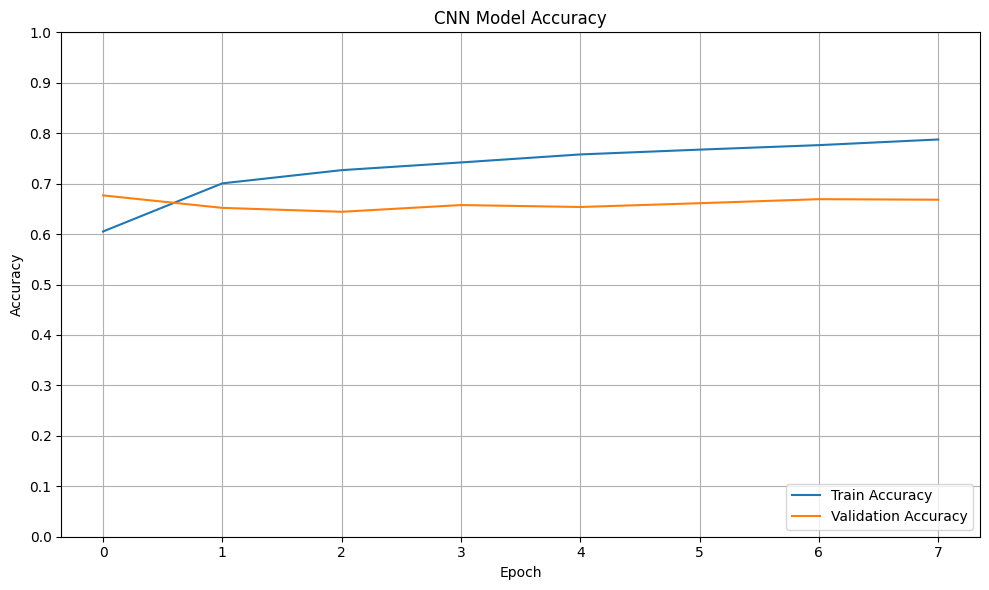

In [ ]:
import matplotlib.pyplot as plt
import os

# Use OUTDIR for consistency
file_dir = OUTDIR

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(hist.history['acc'], label='Train Accuracy')
plt.plot(hist.history['val_acc'], label='Validation Accuracy')
plt.title('CNN Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path = os.path.join(file_dir, 'cnn_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path)
print(f"Accuracy plot saved to: {accuracy_plot_path}")
plt.show()

Loss plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_loss_plot_w.png


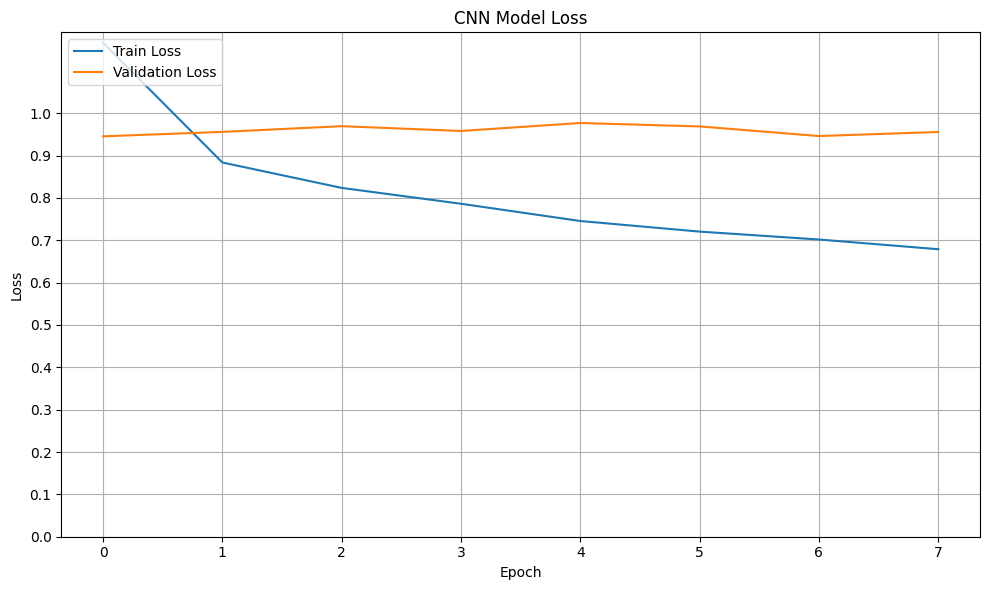

In [ ]:
import matplotlib.pyplot as plt
import os

# Use OUTDIR for consistency
file_dir = OUTDIR

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(hist.history['loss'], label='Train Loss')
plt.plot(hist.history['val_loss'], label='Validation Loss')
plt.title('CNN Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path = os.path.join(file_dir, 'cnn_loss_plot_w.png')
plt.savefig(loss_plot_path)
print(f"Loss plot saved to: {loss_plot_path}")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the training set using the best CNN model (replacing model1d)
y_pred_probs_train_cnn_model1d_eval = cnn.predict(X_train) # Changed X_train to X_train_emb
# Convert probabilities to class labels
y_predict_cnn_model1d_eval_train = np.argmax(y_pred_probs_train_cnn_model1d_eval, axis=1)

# Compute confusion matrix
cm_cnn_model1d_eval_train = confusion_matrix(y_train, y_predict_cnn_model1d_eval_train)
print("Confusion Matrix for Train Data (CNN Model Evaluation ):")
print(cm_cnn_model1d_eval_train)

1750/1750 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step
Confusion Matrix for Train Data (CNN Model Evaluation ):
[[11781   218   522    79  1093]
 [  532  9414   630   210   800]
 [ 1964   747  8159   162  2659]
 [  194   174   182  2574   212]
 [ 2778   539  1861   272  8242]]


Training Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_model1d_eval_train_confusion_matrix_w.png


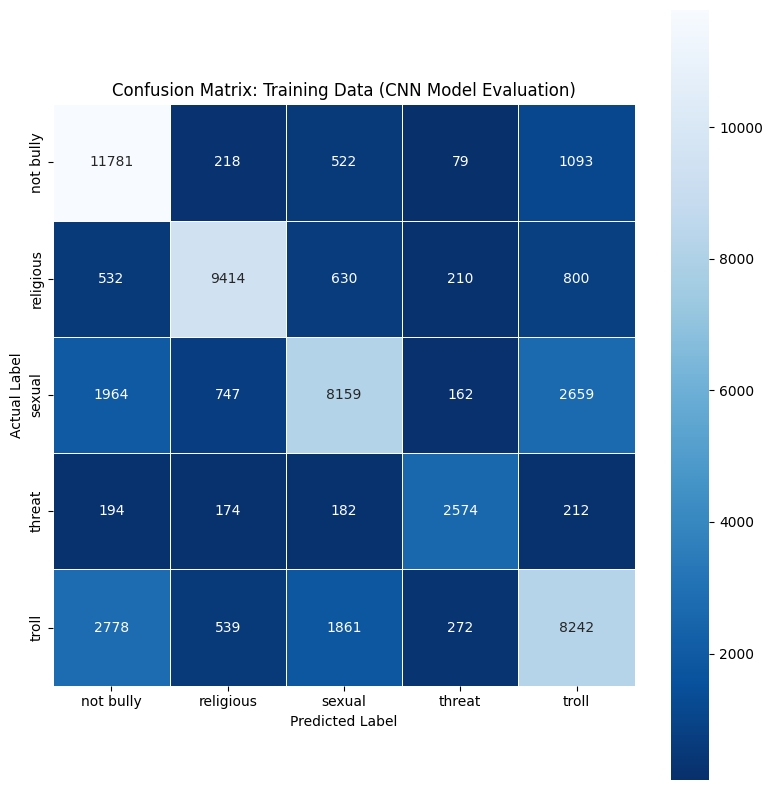

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use OUTDIR for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_cnn_model1d_eval_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes) # Changed le.classes_ to classes
plt.title('Confusion Matrix: Training Data (CNN Model Evaluation)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_cnn_model1d_eval)
print(f"Training Confusion Matrix plot saved to: {train_cm_plot_path_cnn_model1d_eval}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_cnn_model1d_eval_train = classification_report(y_train, y_predict_cnn_model1d_eval_train, target_names=classes)
print("CNN Model1D Evaluation Train Report (now using Best CNN Model):\n", report_cnn_model1d_eval_train)

# Save the report to Google Drive
import os
file_dir = OUTDIR
train_report_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_train_classification_report_w.txt')
with open(train_report_path_cnn_model1d_eval, 'w') as f:
    f.write("CNN Model1D Evaluation Train Report):\n")
    f.write(report_cnn_model1d_eval_train)
print(f"Training Classification Report saved to: {train_report_path_cnn_model1d_eval}")

CNN Model1D Evaluation Train Report (now using Best CNN Model):
               precision    recall  f1-score   support

   not bully       0.68      0.86      0.76     13693
   religious       0.85      0.81      0.83     11586
      sexual       0.72      0.60      0.65     13691
      threat       0.78      0.77      0.78      3336
       troll       0.63      0.60      0.62     13692

    accuracy                           0.72     55998
   macro avg       0.73      0.73      0.73     55998
weighted avg       0.72      0.72      0.71     55998

Training Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_model1d_eval_train_classification_report_w.txt


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the test set using the best CNN model (replacing model1d)
y_pred_probs_test_cnn_model1d_eval = cnn.predict(X_test)
# Convert probabilities to class labels
y_predict_cnn_model1d_eval_test = np.argmax(y_pred_probs_test_cnn_model1d_eval, axis=1)

# Compute confusion matrix
cm_cnn_model1d_eval_test = confusion_matrix(y_test, y_predict_cnn_model1d_eval_test)
print("Confusion Matrix for Test Data (CNN Model1D Evaluation - now using Best CNN Model):")
print(cm_cnn_model1d_eval_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Confusion Matrix for Test Data (CNN Model1D Evaluation - now using Best CNN Model):
[[2344  136  135   89  230]
 [  88 2060  120   98  116]
 [ 339  314 1623  180  478]
 [  40   46   44  552   32]
 [ 533  270  414  219 1497]]


Test Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_model1d_eval_test_confusion_matrix_w.png


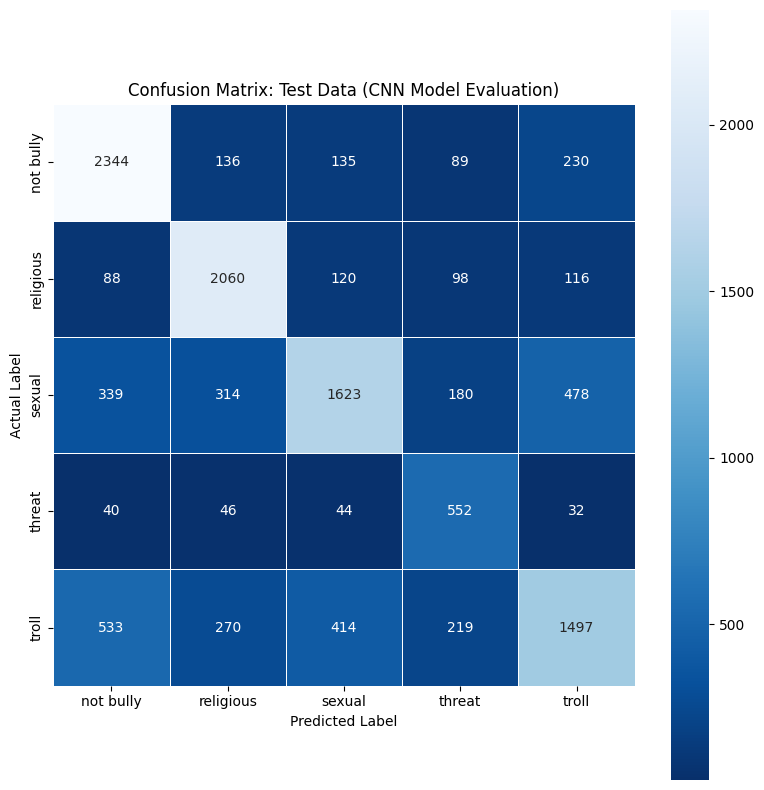

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use OUTDIR for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_cnn_model1d_eval_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Test Data (CNN Model Evaluation)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_cnn_model1d_eval)
print(f"Test Confusion Matrix plot saved to: {test_cm_plot_path_cnn_model1d_eval}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_cnn_model1d_eval_test = classification_report(y_test, y_predict_cnn_model1d_eval_test, target_names=classes)
print("CNN Model1D Evaluation Test Report (now using Best CNN Model):\n", report_cnn_model1d_eval_test)

# Save the report to Google Drive
import os
file_dir = OUTDIR
test_report_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_test_classification_report_w.txt')
with open(test_report_path_cnn_model1d_eval, 'w') as f:
    f.write("CNN Model Evaluation Test Report:\n")
    f.write(report_cnn_model1d_eval_test)
print(f"Test Classification Report saved to: {test_report_path_cnn_model1d_eval}")

CNN Model1D Evaluation Test Report (now using Best CNN Model):
               precision    recall  f1-score   support

   not bully       0.70      0.80      0.75      2934
   religious       0.73      0.83      0.78      2482
      sexual       0.69      0.55      0.62      2934
      threat       0.49      0.77      0.60       714
       troll       0.64      0.51      0.57      2933

    accuracy                           0.67     11997
   macro avg       0.65      0.69      0.66     11997
weighted avg       0.68      0.67      0.67     11997

Test Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_model1d_eval_test_classification_report_w.txt


CNN Model1D Evaluation ROC curve plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_model1d_eval_roc_curve_w.png


C:\Users\pciuc\AppData\Local\Temp\ipykernel_20964\1735361747.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('jet', n_classes)


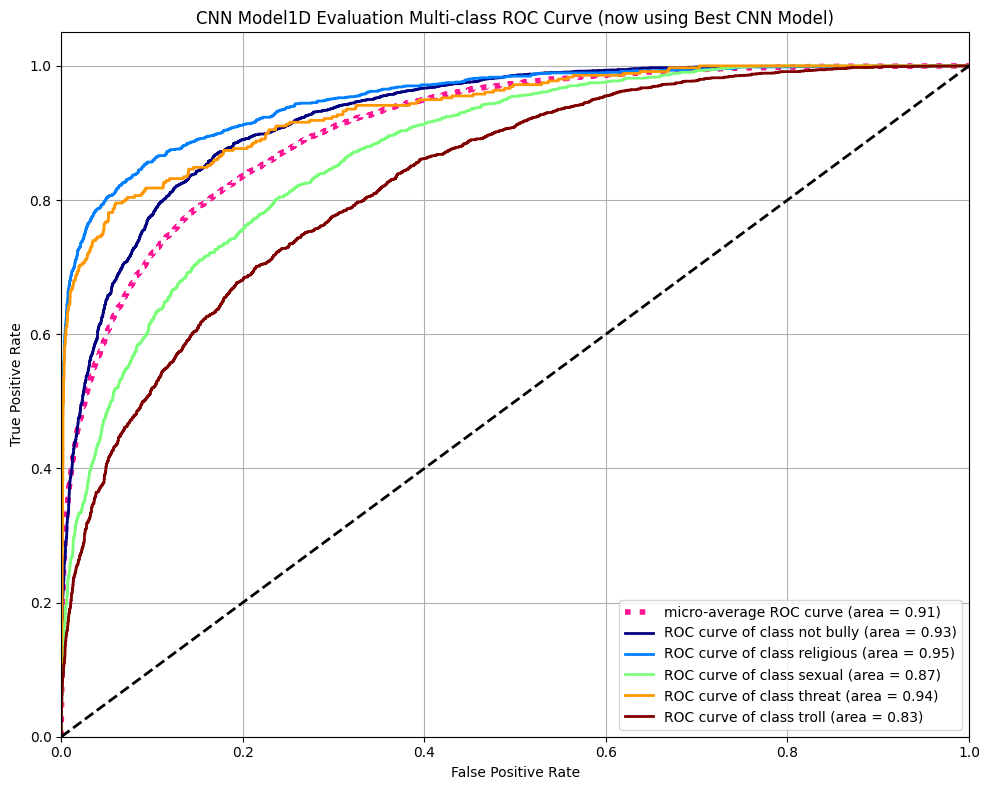

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical
import os

# Use OUTDIR for consistency
file_dir = OUTDIR

# Get the number of classes
n_classes = len(classes)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr_cnn_model1d_eval = dict()
tpr_cnn_model1d_eval = dict()
roc_auc_cnn_model1d_eval = dict()
for i in range(n_classes):
    fpr_cnn_model1d_eval[i], tpr_cnn_model1d_eval[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_cnn_model1d_eval[:, i])
    roc_auc_cnn_model1d_eval[i] = auc(fpr_cnn_model1d_eval[i], tpr_cnn_model1d_eval[i])

# Compute micro-average ROC curve and ROC area
fpr_micro_cnn_model1d_eval, tpr_micro_cnn_model1d_eval, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_cnn_model1d_eval.ravel())
roc_auc_micro_cnn_model1d_eval = auc(fpr_micro_cnn_model1d_eval, tpr_micro_cnn_model1d_eval)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_cnn_model1d_eval, tpr_micro_cnn_model1d_eval,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro_cnn_model1d_eval),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr_cnn_model1d_eval[i], tpr_cnn_model1d_eval[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(classes[i], roc_auc_cnn_model1d_eval[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('CNN Model1D Evaluation Multi-class ROC Curve (now using Best CNN Model)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_cnn_model1d_eval = os.path.join(file_dir, 'cnn_model1d_eval_roc_curve_w.png')
plt.savefig(roc_plot_path_cnn_model1d_eval)
print(f"CNN Model1D Evaluation ROC curve plot saved to: {roc_plot_path_cnn_model1d_eval}")
plt.show()

In [ ]:
# ================================ CELL 31 =====================================
# Is the gap GROWING (overfitting) or FLAT (structural)? Slope decides.
def gap_report(hist, tail=10):
    h = hist.history
    tr = np.array(h.get("h_tr_f1", h["acc"]));  va = np.array(h["val_macro_f1"])
    gap = (tr - va) * 100
    n = len(gap)
    print(f"{'epoch':>6}{'honest train':>14}{'val macro-F1':>14}{'gap (pp)':>11}")
    for e in sorted({0, 1, 2, n // 2, n - 3, n - 2, n - 1} & set(range(n))):
        print(f"{e+1:>6}{tr[e]*100:>13.2f}%{va[e]*100:>13.2f}%{gap[e]:>+11.2f}")
    k = min(tail, n)
    slope = np.polyfit(np.arange(k), gap[-k:], 1)[0]
    print(f"\npeak gap {gap.max():+.2f} pp at epoch {int(gap.argmax())+1} "
          f"| final {gap[-1]:+.2f} pp")
    print(f"slope over last {k} epochs: {slope:+.4f} pp/epoch")
    if slope > 0.05:
        print("-> STILL MEMORISING. Raise DROP_MID/DROP_HEAD or cut patience.")
    else:
        print("-> gap is FLAT. Not overfitting; this is the label-noise floor.")
        if va[-1] >= va[:-1].max():
            print("-> val was STILL IMPROVING at the last epoch. Raise `epochs`.")
    return gap

gap = gap_report(hist)

 epoch  honest train  val macro-F1   gap (pp)
     1        72.82%        65.96%      +6.86
     2        74.69%        62.76%     +11.94
     3        77.10%        62.28%     +14.82
     5        81.21%        63.33%     +17.88
     6        82.78%        64.09%     +18.69
     7        83.55%        64.93%     +18.62
     8        84.83%        64.76%     +20.07

peak gap +20.07 pp at epoch 8 | final +20.07 pp
slope over last 8 epochs: +1.6595 pp/epoch
-> STILL MEMORISING. Raise DROP_MID/DROP_HEAD or cut patience.


In [ ]:
import os

# Save the best CNN model with the '_w' suffix
model_save_path_best_cnn = os.path.join(OUTDIR, 'CNN_model_best_w.keras')
cnn.save(model_save_path_best_cnn)
print(f"Best CNN model saved to: {model_save_path_best_cnn}")

# You can now proceed to generate plots and reports for 'model'
# using similar code blocks as the original CNN model, applying the '_w' suffix.

Best CNN model saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\CNN_model_best_w.keras


In [ ]:
# ================================ CELL 21 =====================================
import os, time, random
from collections import defaultdict

LABEL_SMOOTH = 0.05      # ~= the 2.82% measured annotator disagreement rate

# ---- per-arm stores: reset every time you flip EMB_ALGO ----------------------
RESULTS, PREDS = {}, {}

# ---- cross-arm stores: created ONCE, must survive both arms ------------------
try:
    ALL_RUNS
except NameError:
    ALL_RUNS, PRED_ALL = [], {}

# positional, not label-based -- robust even if `test` is ever filtered/reindexed
KEEP    = np.flatnonzero(~test["text_clean"].duplicated().values)   # 8,764
KEEP_TR = np.flatnonzero(~train["text_clean"].duplicated().values)  # 40,902

# one-hot targets, because label_smoothing cannot work on integer labels
Y_train  = keras.utils.to_categorical(y_train, NUM_CLASSES)
Y_val    = keras.utils.to_categorical(y_val,   NUM_CLASSES)
sw_train = np.array([class_weight_by_id[i] for i in y_train], dtype="float32")
sw_val   = np.array([class_weight_by_id[i] for i in y_val],   dtype="float32")


def reset_seeds():
    keras.backend.clear_session()
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)


def train_and_report(name, model, epochs=30, batch_size=128, patience=5, verbose=2):
    # compiled HERE, not in the builder cells, so label smoothing is applied in
    # exactly one place. Any compile() inside build_*() is harmlessly overridden.
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH),
        metrics=[keras.metrics.CategoricalAccuracy(name="acc")])

    # arm + seed in the filename, or arm 2 silently overwrites arm 1's weights
    ckpt = f"{EMB_ALGO}_{name}_s{SEED}.weights.h5"      # Keras 2: drop ".weights"
    cbs = [
        MacroF1(X_val, y_val),                   # first: writes the metric others read
        keras.callbacks.ModelCheckpoint(ckpt, monitor="val_macro_f1", mode="max",
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_macro_f1", mode="max",
                                          factor=0.5, patience=2, min_lr=1e-5),
        keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max",
                                      patience=patience, restore_best_weights=True),
    ]

    t0 = time.time()
    hist = model.fit(X_train, Y_train, sample_weight=sw_train,
                     validation_data=(X_val, Y_val, sw_val),
                     epochs=epochs, batch_size=batch_size,
                     callbacks=cbs, verbose=verbose)      # class_weight is GONE
    mins = (time.time() - t0) / 60

    # guarantee the reported numbers come from the best-val epoch, not the last one
    if os.path.exists(ckpt):
        model.load_weights(ckpt)

    n_trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    n_total     = model.count_params()

    pred_tr = model.predict(X_train, batch_size=512, verbose=0).argmax(1)
    pred    = model.predict(X_test,  batch_size=512, verbose=0).argmax(1)
    yt, yp  = y_test[KEEP], pred[KEEP]

    acc_tr_rows = (pred_tr == y_train).mean()                       # inflated by dupes
    acc_tr_uniq = (pred_tr[KEEP_TR] == y_train[KEEP_TR]).mean()     # the honest one
    acc_te      = (yt == yp).mean()
    f1_macro    = f1_score(yt, yp, average="macro", zero_division=0)
    per         = f1_score(yt, yp, average=None, labels=range(NUM_CLASSES),
                           zero_division=0)

    print(f"\n{name} [{EMB_ALGO}, seed {SEED}] | {len(hist.history['loss'])} epochs "
          f"| {mins:.1f} min")
    print(f"params: trainable {n_trainable:,} / total {n_total:,} "
          f"({(1-n_trainable/n_total)*100:.1f}% frozen)")
    print(f"train acc  rows {acc_tr_rows*100:6.2f}%   unique {acc_tr_uniq*100:6.2f}%")
    print(f"test  acc  {acc_te*100:6.2f}%   macro-F1 {f1_macro:.4f}   "
          f"(on {len(KEEP):,} unique comments)")
    print(f"HONEST GAP (unique train - unique test): "
          f"{(acc_tr_uniq - acc_te)*100:+.1f} pp")
    print(classification_report(yt, yp, target_names=id_to_label, digits=4,
                                zero_division=0))
    print(pd.DataFrame(confusion_matrix(yt, yp), index=id_to_label,
                       columns=id_to_label).to_string())

    row = {"model": name, "algo": EMB_ALGO, "seed": SEED,
           "train_acc_rows": acc_tr_rows, "train_acc_unique": acc_tr_uniq,
           "test_acc": acc_te, "gap_pp": (acc_tr_uniq - acc_te) * 100,
           "macro_F1": f1_macro,
           "weighted_F1": f1_score(yt, yp, average="weighted", zero_division=0),
           **{f"F1_{id_to_label[i]}": per[i] for i in range(NUM_CLASSES)},
           "trainable": n_trainable, "total": n_total,
           "epochs": len(hist.history["loss"]), "min": round(mins, 1)}

    RESULTS[name] = row
    PREDS[name]   = pred
    ALL_RUNS.append(row)                                   # survives both arms
    PRED_ALL[(EMB_ALGO, name, SEED)] = pred                # cell 30 reads this
    pd.DataFrame(ALL_RUNS).to_csv(OUTDIR / "all_runs.csv", index=False)
    return hist

LSTM

In [ ]:
LSTM_UNITS = 128
DROP_EMB, DROP_MID, DROP_HEAD, L2 = 0.30, 0.50, 0.60, 1e-5
HEAD_UNITS = 256

from tensorflow.keras import regularizers

def build_lstm():
    inp  = keras.Input(shape=(MAXLEN,), dtype="int32", name="tokens")
    mask = TokenMask(name="mask")(inp)
    x = layers.Embedding(len(vocab), EMB_DIM, weights=[embedding_matrix],
                         trainable=True, name="w2v_embedding")(inp)
    x = layers.SpatialDropout1D(DROP_EMB)(x)

    x = layers.Bidirectional(
        layers.LSTM(LSTM_UNITS, return_sequences=True,
                    recurrent_dropout=0.0),      # 0.0 keeps the cuDNN kernel
        name="bilstm_1")(x, mask=mask)           # explicit mask: 73% of steps are padding

    h = MaskedPool1D(name="masked_pool")([x, mask])          # (None, 512)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_MID)(h)
    h = layers.Dense(HEAD_UNITS, activation="elu", kernel_regularizer=regularizers.l2(L2))(h)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_HEAD)(h)
    out = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(h)

    m = keras.Model(inp, out, name="lstm")
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

reset_seeds()
model_lstm = build_lstm()
model_lstm.summary()
hist_lstm = train_and_report("lstm", model_lstm)

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer)           │ (None, 56)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ w2v_embedding (Embedding)     │ (None, 56, 200)           │      17,172,200 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_dropout1d             │ (None, 56, 200)           │               0 │ w2v_embedding[0][0]        │
│ (SpatialDropout1D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ mask (TokenMask)              │ (None, 56)                │               0 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bilstm_1 (Bidirectional)      │ (None, 56, 256)           │         336,896 │ spatial_dropout1d[0][0],   │
│                               │                           │                 │ mask[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ masked_pool (MaskedPool1D)    │ (None, 512)               │               0 │ bilstm_1[0][0], mask[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 512)               │           2,048 │ masked_pool[0][0]          │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 256)               │         131,328 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 256)               │           1,024 │ dense[0][0]                │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 256)               │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 5)                 │           1,285 │ dropout_1[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 17,644,781 (67.31 MB)

 Trainable params: 17,643,245 (67.30 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/30
   val_macro_f1: 0.7222
438/438 - 105s - 239ms/step - acc: 0.5557 - loss: 1.2908 - val_acc: 0.7167 - val_loss: 0.8701 - val_macro_f1: 0.7222 - learning_rate: 0.0010
Epoch 2/30
   val_macro_f1: 0.7485
438/438 - 78s - 179ms/step - acc: 0.6929 - loss: 0.8944 - val_acc: 0.7499 - val_loss: 0.7936 - val_macro_f1: 0.7485 - learning_rate: 0.0010
Epoch 3/30
   val_macro_f1: 0.7630
438/438 - 78s - 179ms/step - acc: 0.7341 - loss: 0.8138 - val_acc: 0.7656 - val_loss: 0.7584 - val_macro_f1: 0.7630 - learning_rate: 0.0010
Epoch 4/30
   val_macro_f1: 0.7694
438/438 - 78s - 178ms/step - acc: 0.7633 - loss: 0.7526 - val_acc: 0.7713 - val_loss: 0.7527 - val_macro_f1: 0.7694 - learning_rate: 0.0010
Epoch 5/30
   val_macro_f1: 0.7747
438/438 - 78s - 178ms/step - acc: 0.7853 - loss: 0.7062 - val_acc: 0.7750 - val_loss: 0.7481 - val_macro_f1: 0.7747 - learning_rate: 0.0010
Epoch 6/30
   val_macro_f1: 0.7763
438/438 - 79s - 181ms/step - acc: 0.8035 - loss: 0.6644 - val_acc: 0.7801 - val_loss: 0.7

In [ ]:
import json

file_dir = OUTDIR
evaluation_report_path = os.path.join(file_dir, 'lstm_test_full_evaluation_report.txt') # New filename to distinguish
with open(evaluation_report_path, 'w', encoding='utf-8') as f:
    f.write(json.dumps(RESULTS['lstm'], indent=2))
print(f"Full lstm test evaluation report saved to: {evaluation_report_path}")

Full lstm test evaluation report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\lstm_test_full_evaluation_report.txt


In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import os
from tensorflow.keras.losses import CategoricalCrossentropy # Import for manual loss calculation
from tensorflow.keras.utils import to_categorical # Import to_categorical

# Predict probabilities on the test set for the best LSTM model
y_pred_probs_test_best_lstm = model_lstm.predict(X_test, verbose=0)
# Convert probabilities to class labels
y_predict_best_lstm_test = np.argmax(y_pred_probs_test_best_lstm, axis=1)

# Convert y_test to one-hot encoding for evaluate and CategoricalCrossentropy
y_test_one_hot = to_categorical(y_test, num_classes=NUM_CLASSES)

# Evaluate the best model on the test data
loss_lstm, accuracy_lstm = model_lstm.evaluate(X_test, y_test_one_hot, verbose=0) # Use y_test_one_hot
macro_f1_lstm = f1_score(y_test, y_predict_best_lstm_test, average='macro')

# Calculate loss manually using CategoricalCrossentropy and one-hot encoded y_test
cce_loss_fn = CategoricalCrossentropy(from_logits=False) # from_logits=False because softmax activation is used
loss = cce_loss_fn(y_test_one_hot, y_pred_probs_test_best_lstm).numpy() # Use y_test_one_hot

# Calculate accuracy manually
accuracy = (y_test == y_predict_best_lstm_test).mean()

output_text = (
    f'Test Loss of Best LSTM Model: {loss:.4f}\n' +
    f'Test Accuracy of Best LSTM Model: {accuracy:.4f}\n' +
    f'Test Macro F1 Score of Best LSTM Model: {macro_f1_lstm:.4f}'
)

print(output_text)

# Save the output to a text file
file_dir = OUTDIR # Use OUTDIR instead of base_save_dir
output_report_path = os.path.join(file_dir, 'lstm_test_evaluation_metrics_w.txt')
with open(output_report_path, 'w') as f:
    f.write(output_text)
print(f"LSTM test evaluation metrics saved to: {output_report_path}")

# Optionally, retrain the best model with more epochs using the entire dataset or for better generalization
# This step is commented out but can be enabled if further training is desired
# history_best_cnn = best_cnn_model.fit(X_train_1d, y_train, epochs=100, validation_data=(X_test_1d, y_test))

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Test Loss of Best LSTM Model: 0.6014
Test Accuracy of Best LSTM Model: 0.7881
Test Macro F1 Score of Best LSTM Model: 0.7847
LSTM test evaluation metrics saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\lstm_test_evaluation_metrics_w.txt


Best LSTM Model Accuracy plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\lstm_accuracy_plot_w.png


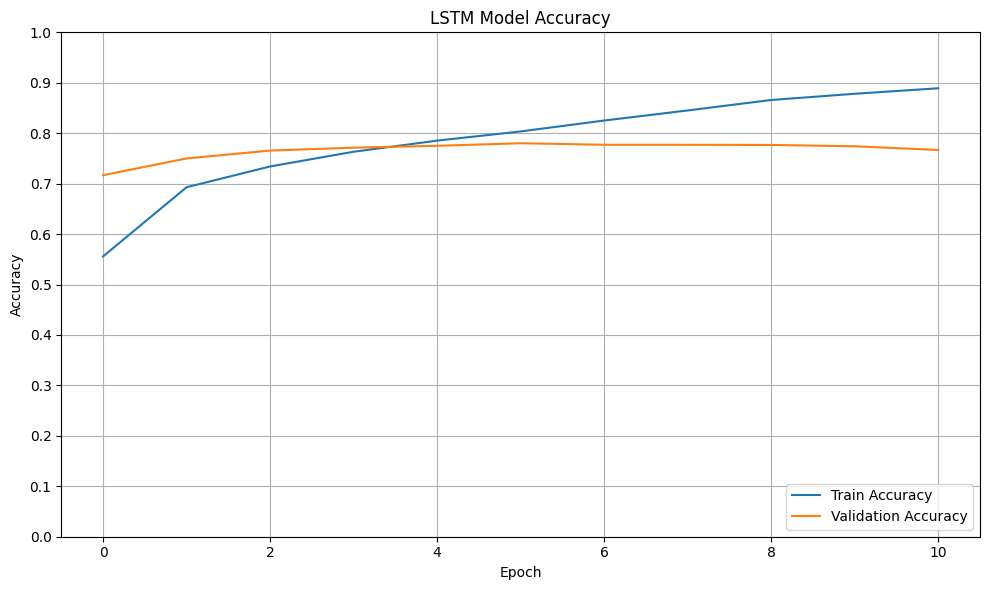

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(hist_lstm.history['acc'], label='Train Accuracy')
plt.plot(hist_lstm.history['val_acc'], label='Validation Accuracy')
plt.title('LSTM Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path_lstm = os.path.join(file_dir, 'lstm_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path_lstm)
print(f"Best LSTM Model Accuracy plot saved to: {accuracy_plot_path_lstm}")
plt.show()

Best LSTM Model Loss plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\lstm_loss_plot_w.png


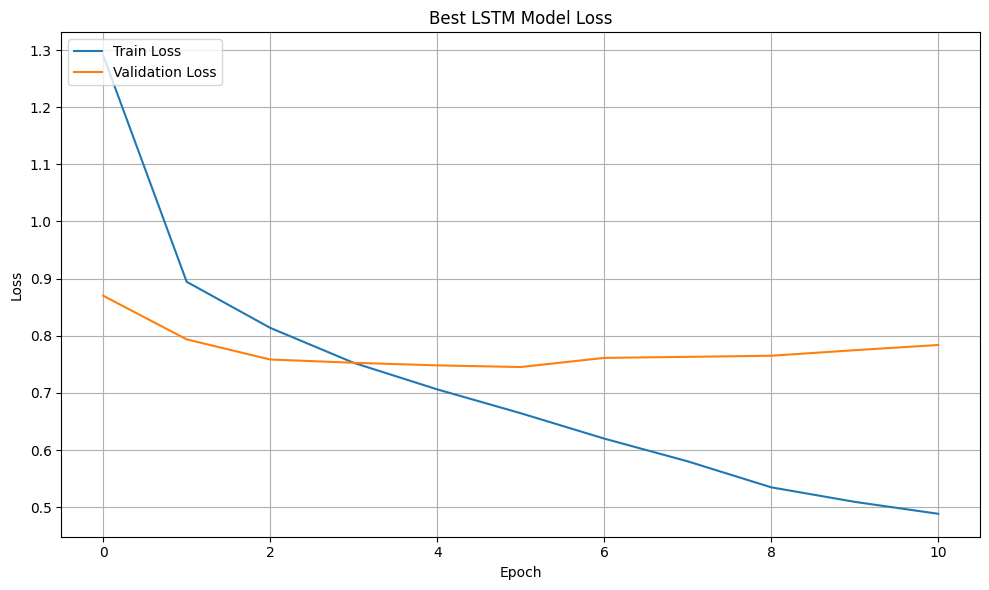

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(hist_lstm.history['loss'], label='Train Loss')
plt.plot(hist_lstm.history['val_loss'], label='Validation Loss')
plt.title('Best LSTM Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path_lstm = os.path.join(file_dir, 'lstm_loss_plot_w.png')
plt.savefig(loss_plot_path_lstm)
print(f"Best LSTM Model Loss plot saved to: {loss_plot_path_lstm}")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the training set for the best LSTM model
y_pred_probs_train_best_lstm = model_lstm.predict(X_train)
# Convert probabilities to class labels
y_predict_best_lstm_train = np.argmax(y_pred_probs_train_best_lstm, axis=1)

# Compute confusion matrix for the best LSTM model on training data
cm_best_lstm_train = confusion_matrix(y_train, y_predict_best_lstm_train)
print("Confusion Matrix for Train Data (Best LSTM Model):")
print(cm_best_lstm_train)

1750/1750 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step
Confusion Matrix for Train Data (Best LSTM Model):
[[12565   155   241    98   634]
 [  166 10482   372   132   434]
 [  650   292 11704    74   971]
 [   10    62    36  3196    32]
 [ 1371   363   698   227 11033]]


Best LSTM Training Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_lstm_train_confusion_matrix_w.png


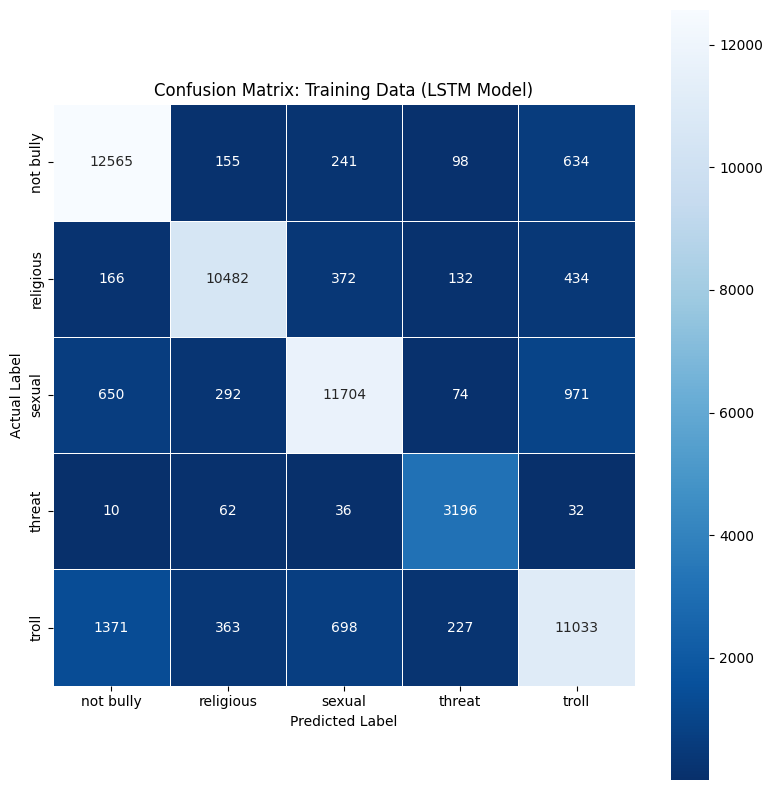

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_lstm_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Training Data (LSTM Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_best_lstm = os.path.join(file_dir, 'best_lstm_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_best_lstm)
print(f"Best LSTM Training Confusion Matrix plot saved to: {train_cm_plot_path_best_lstm}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_lstm_train = classification_report(y_train, y_predict_best_lstm_train, target_names=classes)
print("Best LSTM Train Report:\n", report_best_lstm_train)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
train_report_path_best_lstm = os.path.join(file_dir, 'best_lstm_train_classification_report_w.txt')
with open(train_report_path_best_lstm, 'w') as f:
    f.write("Best LSTM Train Report:\n")
    f.write(report_best_lstm_train)
print(f"Best LSTM Training Classification Report saved to: {train_report_path_best_lstm}")

Best LSTM Train Report:
               precision    recall  f1-score   support

   not bully       0.85      0.92      0.88     13693
   religious       0.92      0.90      0.91     11586
      sexual       0.90      0.85      0.88     13691
      threat       0.86      0.96      0.90      3336
       troll       0.84      0.81      0.82     13692

    accuracy                           0.87     55998
   macro avg       0.87      0.89      0.88     55998
weighted avg       0.88      0.87      0.87     55998

Best LSTM Training Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_lstm_train_classification_report_w.txt


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the test set for the best LSTM model
y_pred_probs_test_best_lstm = model_lstm.predict(X_test)
# Convert probabilities to class labels
y_predict_best_lstm_test = np.argmax(y_pred_probs_test_best_lstm, axis=1)

# Compute confusion matrix for the best LSTM model on test data
cm_best_lstm_test = confusion_matrix(y_test, y_predict_best_lstm_test)
print("Confusion Matrix for Test Data (Best LSTM Model):")
print(cm_best_lstm_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Confusion Matrix for Test Data (Best LSTM Model):
[[2428   72  104   46  284]
 [  62 2150   90   52  128]
 [ 188  101 2237   55  353]
 [  24   30   24  574   62]
 [ 401  115  259   92 2066]]


Best LSTM Test Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_lstm_test_confusion_matrix_w.png


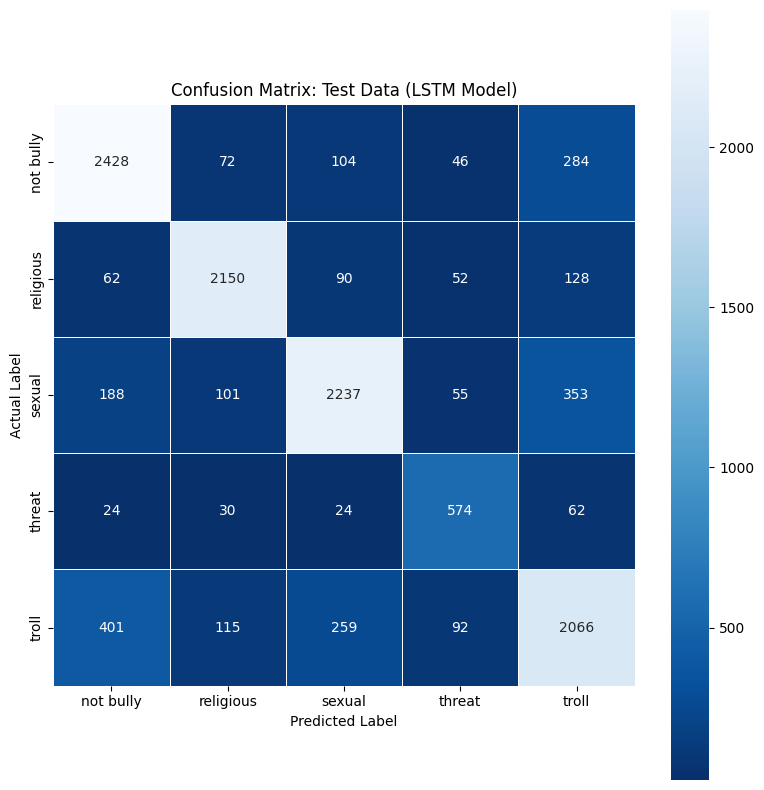

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_lstm_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Test Data (LSTM Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_best_lstm = os.path.join(file_dir, 'best_lstm_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_best_lstm)
print(f"Best LSTM Test Confusion Matrix plot saved to: {test_cm_plot_path_best_lstm}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_lstm_test = classification_report(y_test, y_predict_best_lstm_test, target_names=classes)
print("Best LSTM Test Report:\n", report_best_lstm_test)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
test_report_path_best_lstm = os.path.join(file_dir, 'best_lstm_test_classification_report_w.txt')
with open(test_report_path_best_lstm, 'w') as f:
    f.write("Best LSTM Test Report:\n")
    f.write(report_best_lstm_test)
print(f"Best LSTM Test Classification Report saved to: {test_report_path_best_lstm}")

Best LSTM Test Report:
               precision    recall  f1-score   support

   not bully       0.78      0.83      0.80      2934
   religious       0.87      0.87      0.87      2482
      sexual       0.82      0.76      0.79      2934
      threat       0.70      0.80      0.75       714
       troll       0.71      0.70      0.71      2933

    accuracy                           0.79     11997
   macro avg       0.78      0.79      0.78     11997
weighted avg       0.79      0.79      0.79     11997

Best LSTM Test Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_lstm_test_classification_report_w.txt


Best LSTM Model ROC curve plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_lstm_roc_curve_w.png


C:\Users\pciuc\AppData\Local\Temp\ipykernel_20964\2622506976.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('jet', n_classes)


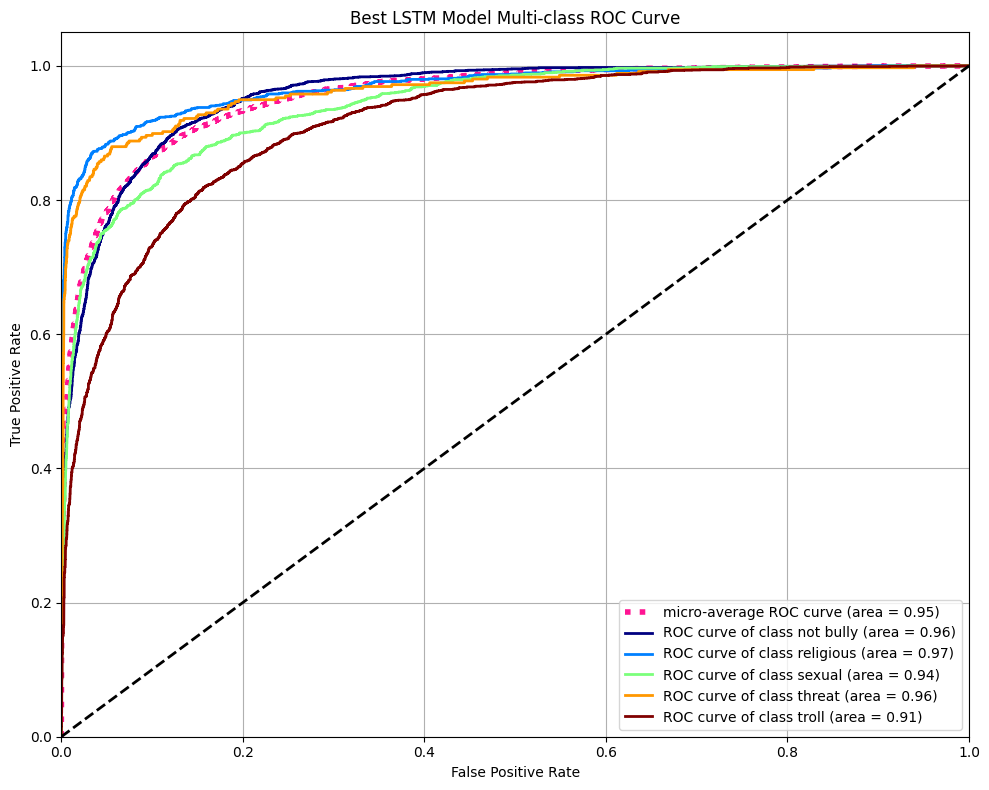

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical
import os

# Use OUTDIR for consistency
file_dir = OUTDIR

# Get the number of classes
n_classes = len(classes)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr_best_lstm = dict()
tpr_best_lstm = dict()
roc_auc_best_lstm = dict()
for i in range(n_classes):
    fpr_best_lstm[i], tpr_best_lstm[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_best_lstm[:, i])
    roc_auc_best_lstm[i] = auc(fpr_best_lstm[i], tpr_best_lstm[i])

# Compute micro-average ROC curve and ROC area
fpr_micro_best_lstm, tpr_micro_best_lstm, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_best_lstm.ravel())
roc_auc_micro_best_lstm = auc(fpr_micro_best_lstm, tpr_micro_best_lstm)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_best_lstm, tpr_micro_best_lstm,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro_best_lstm),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr_best_lstm[i], tpr_best_lstm[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(classes[i], roc_auc_best_lstm[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Best LSTM Model Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_best_lstm = os.path.join(file_dir, 'best_lstm_roc_curve_w.png')
plt.savefig(roc_plot_path_best_lstm)
print(f"Best LSTM Model ROC curve plot saved to: {roc_plot_path_best_lstm}")
plt.show()

In [ ]:
def gap_report(hist_lstm, tail=10):
    h = hist_lstm.history
    tr = np.array(h.get("h_tr_f1", h["acc"]));  va = np.array(h["val_macro_f1"])
    gap = (tr - va) * 100
    n = len(gap)
    print(f"{('epoch'):>6}{('honest train'):>14}{('val macro-F1'):>14}{('gap (pp)'):>11}")
    for e in sorted({0, 1, 2, n // 2, n - 3, n - 2, n - 1} & set(range(n))):
        print(f"{e+1:>6}{tr[e]*100:>13.2f}%{va[e]*100:>13.2f}%{gap[e]:>+11.2f}")
    k = min(tail, n)
    slope = np.polyfit(np.arange(k), gap[-k:], 1)[0]
    print(f"\npeak gap {gap.max():+.2f} pp at epoch {int(gap.argmax())+1} "
          f"| final {gap[-1]:+.2f} pp")
    print(f"slope over last {k} epochs: {slope:+.4f} pp/epoch")
    if slope > 0.05:
        print("-> STILL MEMORISING. Raise DROP_MID/DROP_HEAD or cut patience.")
    else:
        print("-> gap is FLAT. Not overfitting; this is the label-noise floor.")
        if va[-1] >= va[:-1].max():
            print("-> val was STILL IMPROVING at the last epoch. Raise `epochs`.")
    return gap

gap = gap_report(hist_lstm)

 epoch  honest train  val macro-F1   gap (pp)
     1        55.57%        72.22%     -16.66
     2        69.29%        74.85%      -5.56
     3        73.41%        76.30%      -2.90
     6        80.35%        77.63%      +2.72
     9        86.59%        77.26%      +9.33
    10        87.82%        77.11%     +10.71
    11        88.91%        76.28%     +12.63

peak gap +12.63 pp at epoch 11 | final +12.63 pp
slope over last 10 epochs: +1.9946 pp/epoch
-> STILL MEMORISING. Raise DROP_MID/DROP_HEAD or cut patience.


In [ ]:
import os

# Save the best LSTM model with the '_w' suffix
model_save_path_best_lstm = os.path.join(OUTDIR, 'LSTM_model_best_w.keras')
model_lstm.save(model_save_path_best_lstm)
print(f"Best LSTM model saved to: {model_save_path_best_lstm}")

Best LSTM model saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\LSTM_model_best_w.keras


GRU

In [ ]:
GRU_UNITS = 128

from tensorflow.keras import regularizers

def build_gru():
    inp  = keras.Input(shape=(MAXLEN,), dtype="int32", name="tokens")
    mask = TokenMask(name="mask")(inp)
    x = layers.Embedding(len(vocab), EMB_DIM, weights=[embedding_matrix],
                         trainable=True, name="w2v_embedding")(inp)
    x = layers.SpatialDropout1D(DROP_EMB)(x)

    x = layers.Bidirectional(
        layers.GRU(GRU_UNITS, return_sequences=True, recurrent_dropout=0.0),
        name="bigru_1")(x, mask=mask)

    h = MaskedPool1D(name="masked_pool")([x, mask])          # (None, 512)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_MID)(h)
    h = layers.Dense(HEAD_UNITS, activation="elu", kernel_regularizer=regularizers.l2(L2))(h)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_HEAD)(h)
    out = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(h)

    m = keras.Model(inp, out, name="gru")
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

reset_seeds()
model_gru = build_gru()
model_gru.summary()
hist_gru = train_and_report("gru", model_gru)

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer)           │ (None, 56)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ w2v_embedding (Embedding)     │ (None, 56, 200)           │      17,172,200 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_dropout1d             │ (None, 56, 200)           │               0 │ w2v_embedding[0][0]        │
│ (SpatialDropout1D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ mask (TokenMask)              │ (None, 56)                │               0 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bigru_1 (Bidirectional)       │ (None, 56, 256)           │         253,440 │ spatial_dropout1d[0][0],   │
│                               │                           │                 │ mask[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ masked_pool (MaskedPool1D)    │ (None, 512)               │               0 │ bigru_1[0][0], mask[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 512)               │           2,048 │ masked_pool[0][0]          │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 256)               │         131,328 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 256)               │           1,024 │ dense[0][0]                │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 256)               │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 5)                 │           1,285 │ dropout_1[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 17,561,325 (66.99 MB)

 Trainable params: 17,559,789 (66.99 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/30
   val_macro_f1: 0.7133
438/438 - 61s - 140ms/step - acc: 0.5504 - loss: 1.3055 - val_acc: 0.7126 - val_loss: 0.8850 - val_macro_f1: 0.7133 - learning_rate: 0.0010
Epoch 2/30
   val_macro_f1: 0.7430
438/438 - 57s - 130ms/step - acc: 0.6867 - loss: 0.9065 - val_acc: 0.7434 - val_loss: 0.8115 - val_macro_f1: 0.7430 - learning_rate: 0.0010
Epoch 3/30
   val_macro_f1: 0.7544
438/438 - 57s - 131ms/step - acc: 0.7294 - loss: 0.8171 - val_acc: 0.7568 - val_loss: 0.7774 - val_macro_f1: 0.7544 - learning_rate: 0.0010
Epoch 4/30
   val_macro_f1: 0.7647
438/438 - 57s - 130ms/step - acc: 0.7590 - loss: 0.7582 - val_acc: 0.7677 - val_loss: 0.7582 - val_macro_f1: 0.7647 - learning_rate: 0.0010
Epoch 5/30
   val_macro_f1: 0.7640
438/438 - 57s - 131ms/step - acc: 0.7850 - loss: 0.7069 - val_acc: 0.7706 - val_loss: 0.7540 - val_macro_f1: 0.7640 - learning_rate: 0.0010
Epoch 6/30
   val_macro_f1: 0.7580
438/438 - 57s - 130ms/step - acc: 0.8079 - loss: 0.6524 - val_acc: 0.7688 - val_loss: 0.76

In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import os
from tensorflow.keras.losses import CategoricalCrossentropy # Import for manual loss calculation
from tensorflow.keras.utils import to_categorical # Import to_categorical

# Predict probabilities on the test set for the best LSTM model
y_pred_probs_test_best_gru = model_gru.predict(X_test, verbose=0)
# Convert probabilities to class labels
y_predict_gru_test = np.argmax(y_pred_probs_test_best_gru, axis=1)

# Convert y_test to one-hot encoding for evaluate and CategoricalCrossentropy
y_test_one_hot = to_categorical(y_test, num_classes=NUM_CLASSES)

# Evaluate the best model on the test data
loss_gru, accuracy_gru = model_gru.evaluate(X_test, y_test_one_hot, verbose=0)
macro_f1_gru = f1_score(y_test, y_predict_gru_test, average='macro')

# Calculate loss manually using CategoricalCrossentropy and one-hot encoded y_test
cce_loss_fn = CategoricalCrossentropy(from_logits=False) # from_logits=False because softmax activation is used
loss = cce_loss_fn(y_test_one_hot, y_pred_probs_test_best_gru).numpy() # Use y_test_one_hot

# Calculate accuracy manually
accuracy = (y_test == y_predict_gru_test).mean()

output_text = (
    f'Test Loss of Best GRU Model: {loss:.4f}\n' +
    f'Test Accuracy of Best GRU Model: {accuracy:.4f}\n' +
    f'Test Macro F1 Score of Best GRU Model: {macro_f1_gru:.4f}'
)

print(output_text)

# Save the output to a text file
file_dir = OUTDIR # Use OUTDIR instead of base_save_dir
output_report_path = os.path.join(file_dir, 'gru_test_evaluation_metrics_w.txt')
with open(output_report_path, 'w') as f:
    f.write(output_text)
print(f"GRU test evaluation metrics saved to: {output_report_path}")

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Test Loss of Best GRU Model: 0.6223
Test Accuracy of Best GRU Model: 0.7768
Test Macro F1 Score of Best GRU Model: 0.7730
GRU test evaluation metrics saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_test_evaluation_metrics_w.txt


GRU Accuracy plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_accuracy_plot_w.png


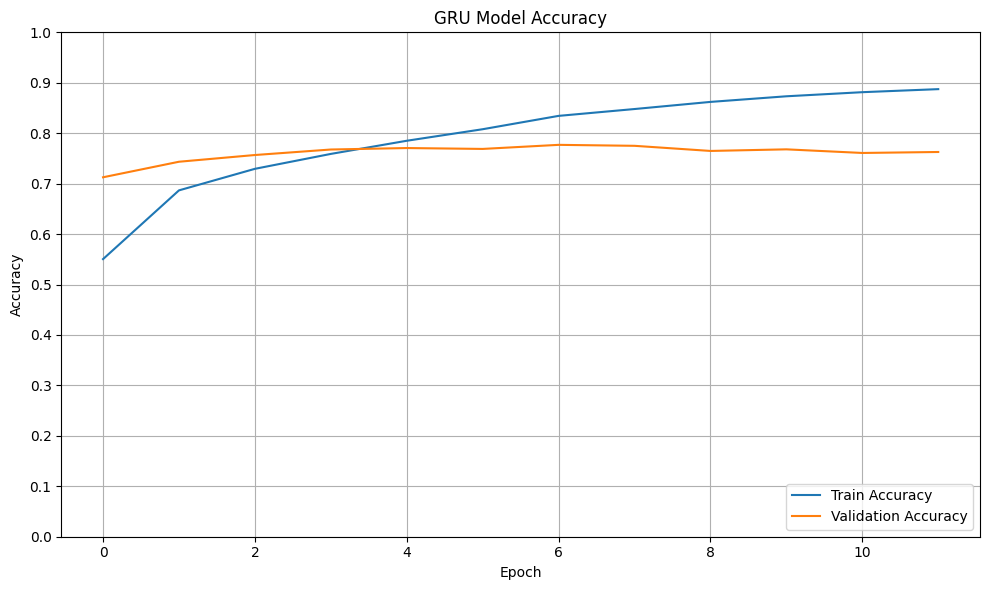

In [ ]:
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(hist_gru.history['acc'], label='Train Accuracy')
plt.plot(hist_gru.history['val_acc'], label='Validation Accuracy')
plt.title('GRU Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path_gru = os.path.join(file_dir, 'gru_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path_gru)
print(f"GRU Accuracy plot saved to: {accuracy_plot_path_gru}")
plt.show()

GRU Loss plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_loss_plot_w.png


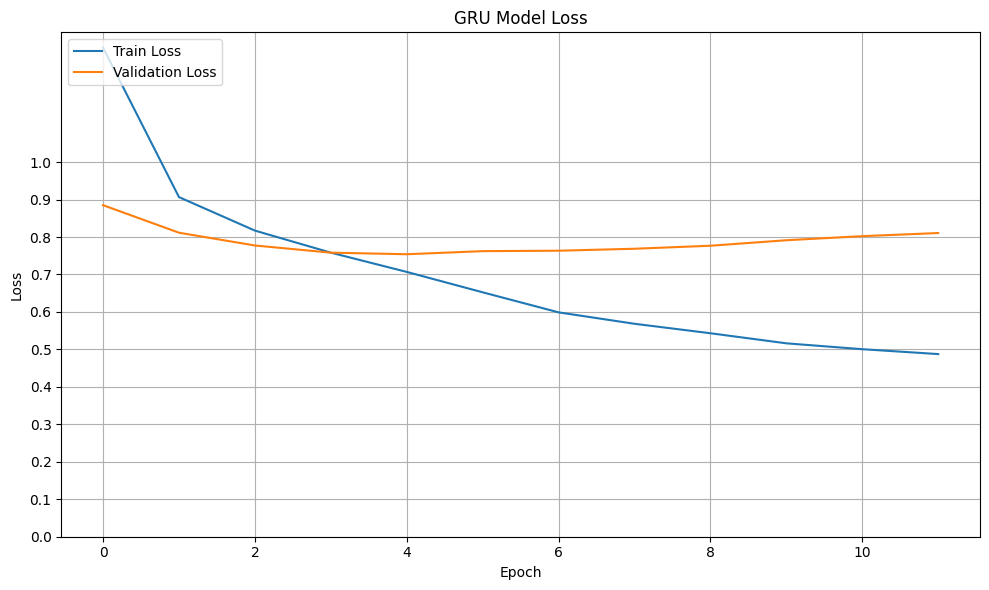

In [ ]:
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(hist_gru.history['loss'], label='Train Loss')
plt.plot(hist_gru.history['val_loss'], label='Validation Loss')
plt.title('GRU Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path_gru = os.path.join(file_dir, 'gru_loss_plot_w.png')
plt.savefig(loss_plot_path_gru)
print(f"GRU Loss plot saved to: {loss_plot_path_gru}")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the training set
y_pred_probs_train_gru = model_gru.predict(X_train)
# Convert probabilities to class labels
y_predict_gru_train = np.argmax(y_pred_probs_train_gru, axis=1)

# Compute confusion matrix
cm_gru_train = confusion_matrix(y_train, y_predict_gru_train)
print("Confusion Matrix for Train Data (GRU):")
print(cm_gru_train)

1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step
Confusion Matrix for Train Data (GRU):
[[12599   163   235    83   613]
 [  106 10762   330   112   276]
 [  391   206 12338    53   703]
 [    6    24     4  3292    10]
 [ 1028   366   703   207 11388]]


GRU Training Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_train_confusion_matrix_w.png


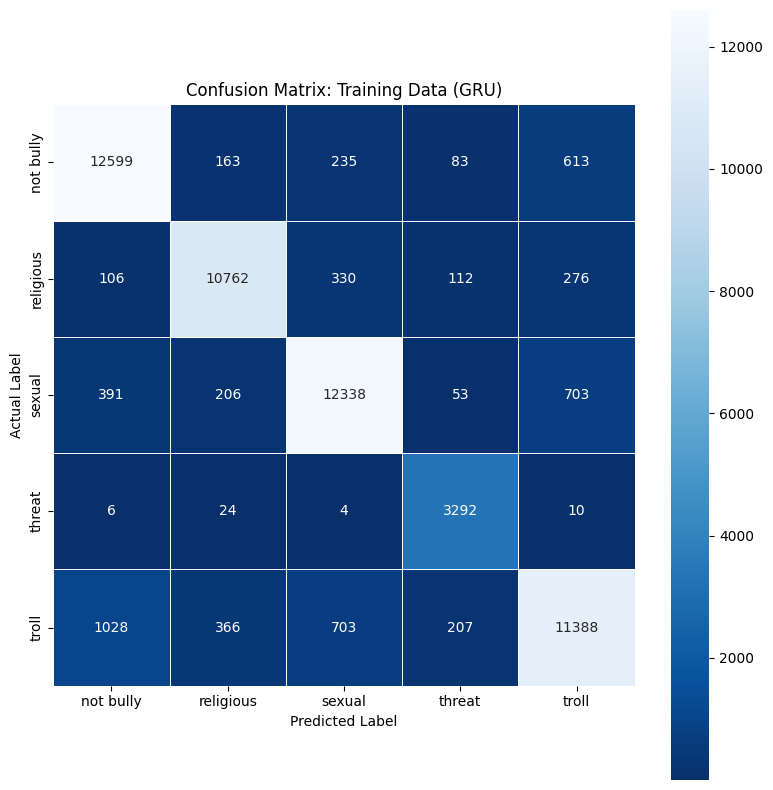

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_gru_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Training Data (GRU)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_gru = os.path.join(file_dir, 'gru_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_gru)
print(f"GRU Training Confusion Matrix plot saved to: {train_cm_plot_path_gru}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_gru_train = classification_report(y_train, y_predict_gru_train, target_names=classes)
print("GRU Train Report:\n", report_gru_train)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
train_report_path_gru = os.path.join(file_dir, 'gru_train_classification_report_w.txt')
with open(train_report_path_gru, 'w') as f:
    f.write("GRU Train Report:\n")
    f.write(report_gru_train)
print(f"GRU Training Classification Report saved to: {train_report_path_gru}")

GRU Train Report:
               precision    recall  f1-score   support

   not bully       0.89      0.92      0.91     13693
   religious       0.93      0.93      0.93     11586
      sexual       0.91      0.90      0.90     13691
      threat       0.88      0.99      0.93      3336
       troll       0.88      0.83      0.85     13692

    accuracy                           0.90     55998
   macro avg       0.90      0.91      0.90     55998
weighted avg       0.90      0.90      0.90     55998

GRU Training Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_train_classification_report_w.txt


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the test set
y_pred_probs_test_gru = model_gru.predict(X_test)
# Convert probabilities to class labels
y_predict_gru_test = np.argmax(y_pred_probs_test_gru, axis=1)

# Compute confusion matrix
cm_gru_test = confusion_matrix(y_test, y_predict_gru_test)
print("Confusion Matrix for Test Data (GRU):")
print(cm_gru_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Confusion Matrix for Test Data (GRU):
[[2367   71  191   54  251]
 [  68 2142  126   54   92]
 [ 182  113 2279   51  309]
 [  24   28   38  572   52]
 [ 376  140  354  104 1959]]


GRU Test Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_test_confusion_matrix_w.png


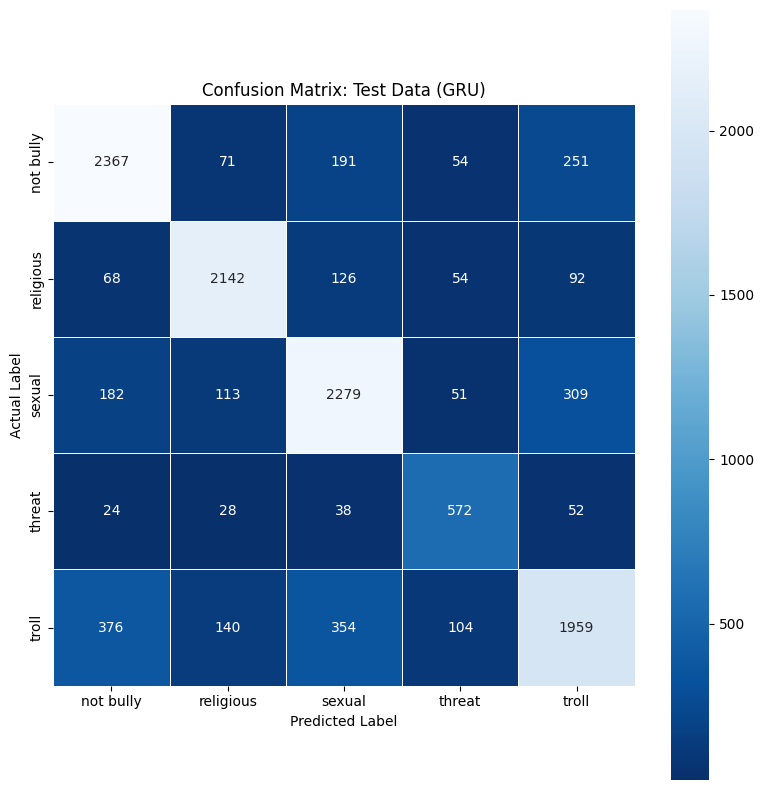

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Derive the directory from where the files were loaded (from a95a5023)
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_gru_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Test Data (GRU)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_gru = os.path.join(file_dir, 'gru_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_gru)
print(f"GRU Test Confusion Matrix plot saved to: {test_cm_plot_path_gru}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_gru_test = classification_report(y_test, y_predict_gru_test, target_names=classes)
print("GRU Test Report:\n", report_gru_test)

# Save the report to Google Drive
import os
file_dir = OUTDIR
test_report_path_gru = os.path.join(file_dir, 'gru_test_classification_report_w.txt')
with open(test_report_path_gru, 'w') as f:
    f.write("GRU Test Report:\n")
    f.write(report_gru_test)
print(f"GRU Test Classification Report saved to: {test_report_path_gru}")

GRU Test Report:
               precision    recall  f1-score   support

   not bully       0.78      0.81      0.80      2934
   religious       0.86      0.86      0.86      2482
      sexual       0.76      0.78      0.77      2934
      threat       0.69      0.80      0.74       714
       troll       0.74      0.67      0.70      2933

    accuracy                           0.78     11997
   macro avg       0.77      0.78      0.77     11997
weighted avg       0.78      0.78      0.78     11997

GRU Test Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_test_classification_report_w.txt


C:\Users\pciuc\AppData\Local\Temp\ipykernel_20964\3321956341.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('jet', n_classes)


GRU ROC curve plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\gru_roc_curve_w.png


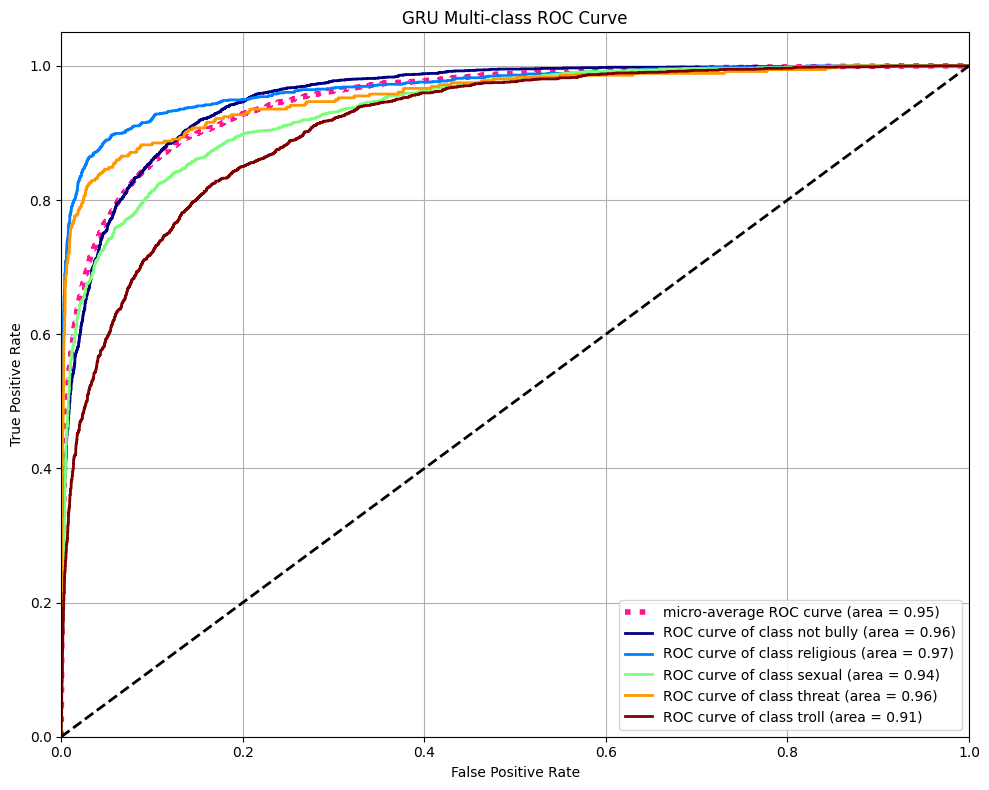

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Get the number of classes
n_classes = len(classes)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_gru[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr_micro, tpr_micro, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_gru.ravel())
roc_auc_micro = auc(fpr_micro, tpr_micro)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro, tpr_micro,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro),
         color='deeppink', linestyle=':', linewidth=4)

# Revert to the older method as matplotlib.colormaps was not found
colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(classes[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('GRU Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_gru = os.path.join(file_dir, 'gru_roc_curve_w.png')
plt.savefig(roc_plot_path_gru)
print(f"GRU ROC curve plot saved to: {roc_plot_path_gru}")
plt.show()

In [ ]:
import os

# Save the best GRU model with the '_w' suffix
model_save_path_best_gru = os.path.join(OUTDIR, 'GRU_model_best_w.keras')
model_gru.save(model_save_path_best_gru)
print(f"Best GRU model saved to: {model_save_path_best_gru}")

Best GRU model saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\GRU_model_best_w.keras


CNN_LSTM

In [ ]:
HYB_FILTERS, HYB_KERNELS = 64, (2, 3, 4, 5)

from tensorflow.keras import regularizers

def build_cnn_lstm():
    inp  = keras.Input(shape=(MAXLEN,), dtype="int32", name="tokens")
    mask = TokenMask(name="mask")(inp)
    x = layers.Embedding(len(vocab), EMB_DIM, weights=[embedding_matrix],
                         trainable=True, name="w2v_embedding")(inp)
    x = layers.SpatialDropout1D(DROP_EMB)(x)

    # parallel k-gram detectors; padding='same' + concat on the FEATURE axis
    # keeps T = MAXLEN, so the same mask still applies downstream
    br = [layers.Conv1D(HYB_FILTERS, k, padding="same", activation="elu",
                        kernel_regularizer=regularizers.l2(L2), name=f"conv{k}")(x)
          for k in HYB_KERNELS]
    x = layers.Concatenate(name="conv_concat")(br)           # (None, 56, 256)

    x = layers.Bidirectional(
        layers.LSTM(128, return_sequences=True, recurrent_dropout=0.0),
        name="bilstm_1")(x, mask=mask)

    h = MaskedPool1D(name="masked_pool")([x, mask])          # (None, 512)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_MID)(h)
    h = layers.Dense(HEAD_UNITS, activation="elu", kernel_regularizer=regularizers.l2(L2))(h)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_HEAD)(h)
    out = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(h)

    m = keras.Model(inp, out, name="cnn_lstm")
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

reset_seeds()
model_cnn_lstm = build_cnn_lstm()
model_cnn_lstm.summary()
hist_cnn_lstm = train_and_report("cnn_lstm", model_cnn_lstm)

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer)           │ (None, 56)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ w2v_embedding (Embedding)     │ (None, 56, 200)           │      17,172,200 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_dropout1d             │ (None, 56, 200)           │               0 │ w2v_embedding[0][0]        │
│ (SpatialDropout1D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2 (Conv1D)                │ (None, 56, 64)            │          25,664 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv3 (Conv1D)                │ (None, 56, 64)            │          38,464 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv4 (Conv1D)                │ (None, 56, 64)            │          51,264 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv5 (Conv1D)                │ (None, 56, 64)            │          64,064 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv_concat (Concatenate)     │ (None, 56, 256)           │               0 │ conv2[0][0], conv3[0][0],  │
│                               │                           │                 │ conv4[0][0], conv5[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ mask (TokenMask)              │ (None, 56)                │               0 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bilstm_1 (Bidirectional)      │ (None, 56, 256)           │         394,240 │ conv_concat[0][0],         │
│                               │                           │                 │ mask[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ masked_pool (MaskedPool1D)    │ (None, 512)               │               0 │ bilstm_1[0][0], mask[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 512)               │           2,048 │ masked_pool[0][0]          │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 256)               │         131,328 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 256)               │           1,024 │ dense[0][0]                │
│ (BatchNormalization)          │                           │               

 Total params: 17,881,581 (68.21 MB)

 Trainable params: 17,880,045 (68.21 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/30
   val_macro_f1: 0.6937
438/438 - 71s - 162ms/step - acc: 0.5524 - loss: 1.3212 - val_acc: 0.6895 - val_loss: 0.9065 - val_macro_f1: 0.6937 - learning_rate: 0.0010
Epoch 2/30
   val_macro_f1: 0.7255
438/438 - 66s - 151ms/step - acc: 0.6870 - loss: 0.9051 - val_acc: 0.7229 - val_loss: 0.8310 - val_macro_f1: 0.7255 - learning_rate: 0.0010
Epoch 3/30
   val_macro_f1: 0.7488
438/438 - 65s - 149ms/step - acc: 0.7303 - loss: 0.8186 - val_acc: 0.7474 - val_loss: 0.8060 - val_macro_f1: 0.7488 - learning_rate: 0.0010
Epoch 4/30
   val_macro_f1: 0.7656
438/438 - 65s - 148ms/step - acc: 0.7638 - loss: 0.7482 - val_acc: 0.7618 - val_loss: 0.7968 - val_macro_f1: 0.7656 - learning_rate: 0.0010
Epoch 5/30
   val_macro_f1: 0.7533
438/438 - 65s - 148ms/step - acc: 0.7890 - loss: 0.6955 - val_acc: 0.7591 - val_loss: 0.7870 - val_macro_f1: 0.7533 - learning_rate: 0.0010
Epoch 6/30
   val_macro_f1: 0.7536
438/438 - 65s - 148ms/step - acc: 0.8156 - loss: 0.6390 - val_acc: 0.7549 - val_loss: 0.84

In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import os
from tensorflow.keras.losses import CategoricalCrossentropy # Import for manual loss calculation
from tensorflow.keras.utils import to_categorical # Import to_categorical

# Evaluate the best model on the test data
# Predict probabilities on the test set for the best CNN-LSTM model
y_pred_probs_test_best_cnn_lstm = model_cnn_lstm.predict(X_test, verbose=0)
# Convert probabilities to class labels
y_predict_best_cl_test = np.argmax(y_pred_probs_test_best_cnn_lstm, axis=1)

# Convert y_test to one-hot encoding for evaluate
y_test_one_hot = to_categorical(y_test, num_classes=NUM_CLASSES) # NEW LINE

loss_cnn_lstm, accuracy_cnn_lstm = model_cnn_lstm.evaluate(X_test, y_test_one_hot, verbose=0) # MODIFIED LINE
macro_f1_cnn_lstm = f1_score(y_test, y_predict_best_cl_test, average='macro')

# Calculate loss manually using CategoricalCrossentropy and one-hot encoded y_test # NEW BLOCK
cce_loss_fn = CategoricalCrossentropy(from_logits=False) # from_logits=False because softmax activation is used
loss = cce_loss_fn(y_test_one_hot, y_pred_probs_test_best_cnn_lstm).numpy() # MODIFIED LINE to use y_test_one_hot

output_text = (
    f'Test Loss of Best CNN-LSTM Model: {loss:.4f}\n' + # MODIFIED to use `loss` variable
    f'Test Accuracy of Best CNN-LSTM Model: {accuracy_cnn_lstm:.4f}\n' +
    f'Test Macro F1 Score of Best CNN-LSTM Model: {macro_f1_cnn_lstm:.4f}'
)

print(output_text)

# Save the output to a text file
file_dir = OUTDIR # Use base_save_dir directly for consistency
output_report_path = os.path.join(file_dir, 'cnn_lstm_test_evaluation_metrics_w.txt')
with open(output_report_path, 'w') as f:
    f.write(output_text)
print(f"CNN-LSTM test evaluation metrics saved to: {output_report_path}")

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Test Loss of Best CNN-LSTM Model: 0.6577
Test Accuracy of Best CNN-LSTM Model: 0.7566
Test Macro F1 Score of Best CNN-LSTM Model: 0.7605
CNN-LSTM test evaluation metrics saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_lstm_test_evaluation_metrics_w.txt


Best CNN-LSTM Accuracy plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_lstm_accuracy_plot_w.png


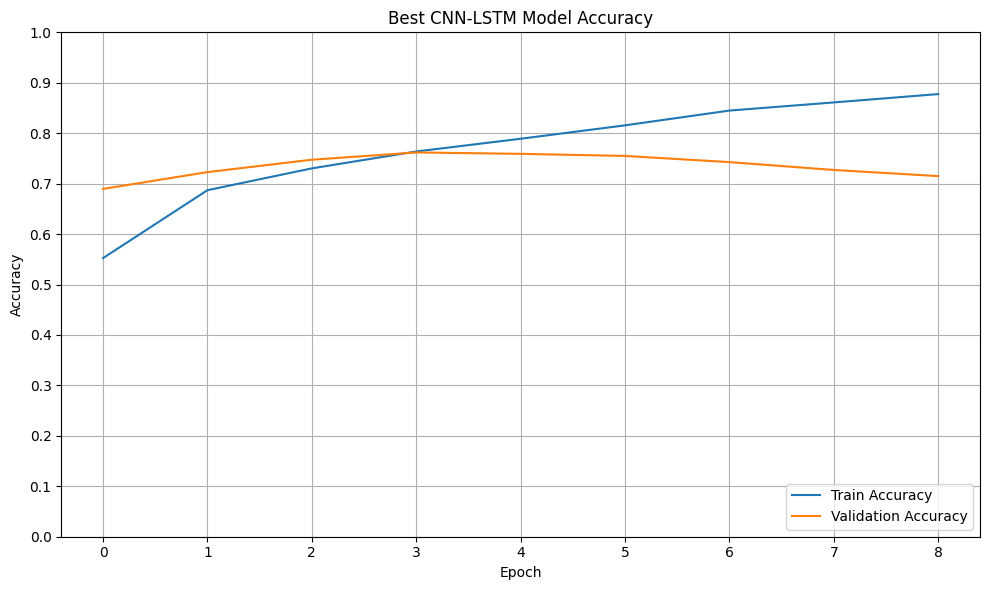

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(hist_cnn_lstm.history['acc'], label='Train Accuracy')
plt.plot(hist_cnn_lstm.history['val_acc'], label='Validation Accuracy')
plt.title('Best CNN-LSTM Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path_best_cnn_lstm = os.path.join(file_dir, 'best_cnn_lstm_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path_best_cnn_lstm)
print(f"Best CNN-LSTM Accuracy plot saved to: {accuracy_plot_path_best_cnn_lstm}")
plt.show()

Best CNN-LSTM Loss plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_lstm_loss_plot_w.png


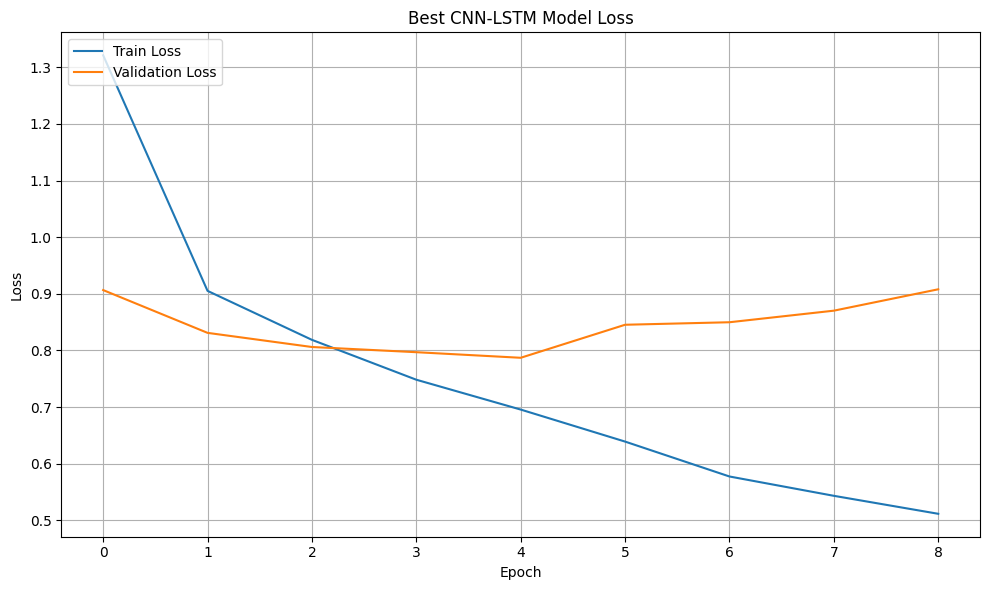

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(hist_cnn_lstm.history['loss'], label='Train Loss')
plt.plot(hist_cnn_lstm.history['val_loss'], label='Validation Loss')
plt.title('Best CNN-LSTM Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path_best_cnn_lstm = os.path.join(file_dir, 'best_cnn_lstm_loss_plot_w.png')
plt.savefig(loss_plot_path_best_cnn_lstm)
print(f"Best CNN-LSTM Loss plot saved to: {loss_plot_path_best_cnn_lstm}")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the training set for the best CNN-LSTM model
y_pred_probs_train_best_cnn_lstm = model_cnn_lstm.predict(X_train)
# Convert probabilities to class labels
y_predict_best_cl_train = np.argmax(y_pred_probs_train_best_cnn_lstm, axis=1)

# Compute confusion matrix for the best CNN-LSTM model on training data
cm_best_cl_train = confusion_matrix(y_train, y_predict_best_cl_train)
print("Confusion Matrix for Train Data (Best CNN-LSTM Model):")
print(cm_best_cl_train)

1750/1750 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step
Confusion Matrix for Train Data (Best CNN-LSTM Model):
[[12125   149   225    55  1139]
 [  232 10130   306    92   826]
 [  909   355 10050    63  2314]
 [   54    94    28  3020   140]
 [ 1469   267   559   155 11242]]


Best CNN-LSTM Training Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_lstm_train_confusion_matrix_w.png


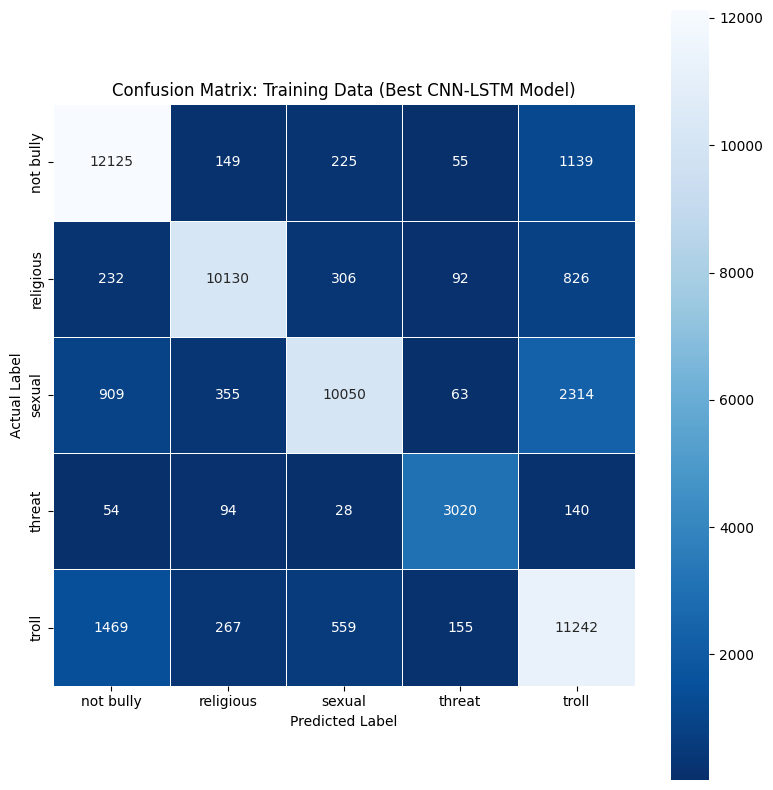

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_cl_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Training Data (Best CNN-LSTM Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_best_cnn_lstm = os.path.join(file_dir, 'best_cnn_lstm_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_best_cnn_lstm)
print(f"Best CNN-LSTM Training Confusion Matrix plot saved to: {train_cm_plot_path_best_cnn_lstm}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_cnn_lstm_train = classification_report(y_train, y_predict_best_cl_train, target_names=classes)
print("Best CNN-LSTM Train Report:\n", report_best_cnn_lstm_train)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
train_report_path_best_cnn_lstm = os.path.join(file_dir, 'best_cnn_lstm_train_classification_report_w.txt')
with open(train_report_path_best_cnn_lstm, 'w') as f:
    f.write("Best CNN-LSTM Train Report:\n")
    f.write(report_best_cnn_lstm_train)
print(f"Best CNN-LSTM Training Classification Report saved to: {train_report_path_best_cnn_lstm}")

Best CNN-LSTM Train Report:
               precision    recall  f1-score   support

   not bully       0.82      0.89      0.85     13693
   religious       0.92      0.87      0.90     11586
      sexual       0.90      0.73      0.81     13691
      threat       0.89      0.91      0.90      3336
       troll       0.72      0.82      0.77     13692

    accuracy                           0.83     55998
   macro avg       0.85      0.84      0.84     55998
weighted avg       0.84      0.83      0.83     55998

Best CNN-LSTM Training Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_lstm_train_classification_report_w.txt


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the test set for the best CNN-LSTM model
y_pred_probs_test_best_cnn_lstm = model_cnn_lstm.predict(X_test)
# Convert probabilities to class labels
y_predict_best_cl_test = np.argmax(y_pred_probs_test_best_cnn_lstm, axis=1)

# Compute confusion matrix for the best CNN-LSTM model on test data
cm_best_cl_test = confusion_matrix(y_test, y_predict_best_cl_test)
print("Confusion Matrix for Test Data (Best CNN-LSTM Model):")
print(cm_best_cl_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step
Confusion Matrix for Test Data (Best CNN-LSTM Model):
[[2317   70   96   37  414]
 [  70 2082   68   52  210]
 [ 226  121 1925   30  632]
 [  26   32   30  542   84]
 [ 365  112  184   61 2211]]


Best CNN-LSTM Test Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_lstm_test_confusion_matrix_w.png


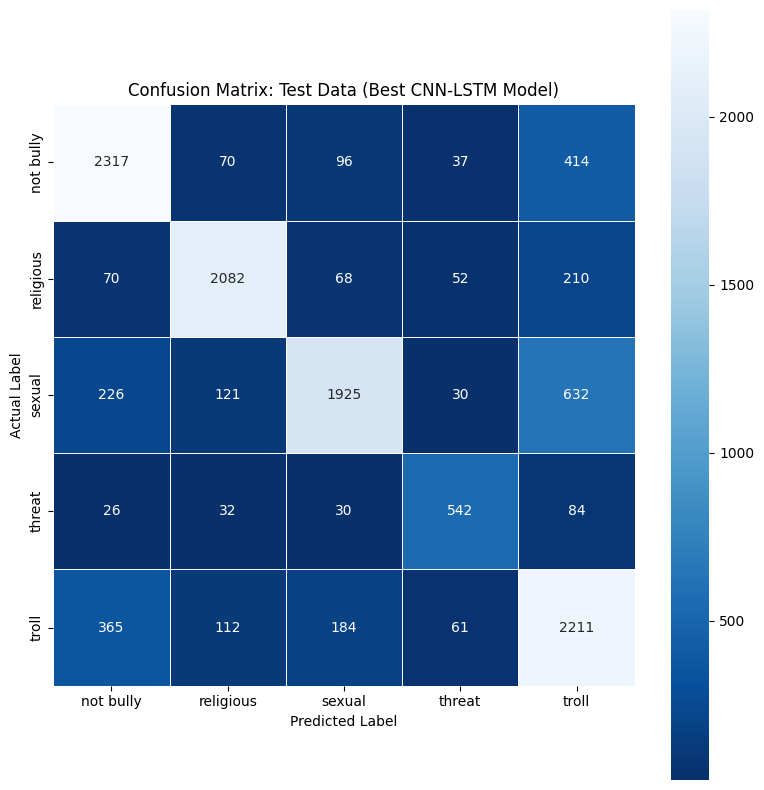

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_cl_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Test Data (Best CNN-LSTM Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_best_cnn_lstm = os.path.join(file_dir, 'best_cnn_lstm_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_best_cnn_lstm)
print(f"Best CNN-LSTM Test Confusion Matrix plot saved to: {test_cm_plot_path_best_cnn_lstm}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_cnn_lstm_test = classification_report(y_test, y_predict_best_cl_test, target_names=classes)
print("Best CNN-LSTM Test Report:\n", report_best_cnn_lstm_test)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
test_report_path_best_cnn_lstm = os.path.join(file_dir, 'best_cnn_lstm_test_classification_report_w.txt')
with open(test_report_path_best_cnn_lstm, 'w') as f:
    f.write("Best CNN-LSTM Test Report:\n")
    f.write(report_best_cnn_lstm_test)
print(f"Best CNN-LSTM Test Classification Report saved to: {test_report_path_best_cnn_lstm}")

Best CNN-LSTM Test Report:
               precision    recall  f1-score   support

   not bully       0.77      0.79      0.78      2934
   religious       0.86      0.84      0.85      2482
      sexual       0.84      0.66      0.74      2934
      threat       0.75      0.76      0.75       714
       troll       0.62      0.75      0.68      2933

    accuracy                           0.76     11997
   macro avg       0.77      0.76      0.76     11997
weighted avg       0.77      0.76      0.76     11997

Best CNN-LSTM Test Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_lstm_test_classification_report_w.txt


Best CNN-LSTM ROC curve plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_lstm_roc_curve_w.png


C:\Users\pciuc\AppData\Local\Temp\ipykernel_20964\859675591.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('jet', n_classes)


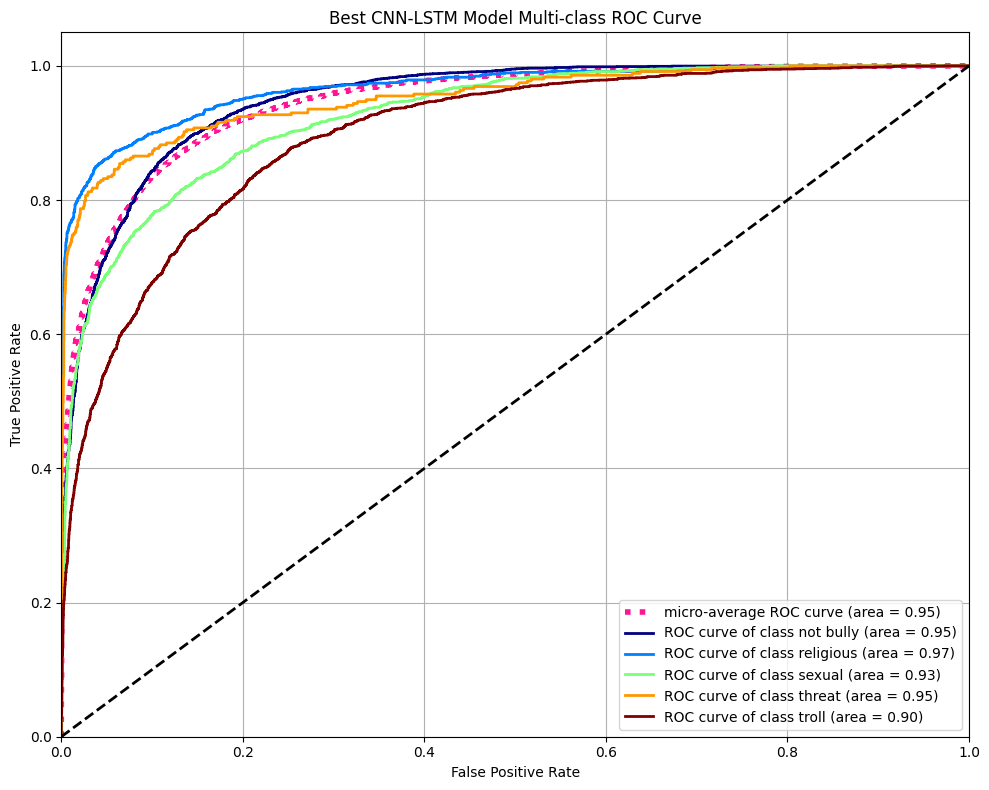

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Get the number of classes
n_classes = len(classes)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr_best_cnn_lstm = dict()
tpr_best_cnn_lstm = dict()
roc_auc_best_cnn_lstm = dict()
for i in range(n_classes):
    fpr_best_cnn_lstm[i], tpr_best_cnn_lstm[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_best_cnn_lstm[:, i])
    roc_auc_best_cnn_lstm[i] = auc(fpr_best_cnn_lstm[i], tpr_best_cnn_lstm[i])

# Compute micro-average ROC curve and ROC area
fpr_micro_best_cnn_lstm, tpr_micro_best_cnn_lstm, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_best_cnn_lstm.ravel())
roc_auc_micro_best_cnn_lstm = auc(fpr_micro_best_cnn_lstm, tpr_micro_best_cnn_lstm)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_best_cnn_lstm, tpr_micro_best_cnn_lstm,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro_best_cnn_lstm),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr_best_cnn_lstm[i], tpr_best_cnn_lstm[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(classes[i], roc_auc_best_cnn_lstm[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Best CNN-LSTM Model Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_best_cnn_lstm = os.path.join(file_dir, 'best_cnn_lstm_roc_curve_w.png')
plt.savefig(roc_plot_path_best_cnn_lstm)
print(f"Best CNN-LSTM ROC curve plot saved to: {roc_plot_path_best_cnn_lstm}")
plt.show()

In [ ]:
import os

# Save the best CNN-LSTM model with the '_w' suffix
model_save_path_best_cnn_lstm = os.path.join(OUTDIR, 'CNN_LSTM_model_best_w.keras')
model_cnn_lstm.save(model_save_path_best_cnn_lstm)
print(f"Best CNN-LSTM model saved to: {model_save_path_best_cnn_lstm}")

Best CNN-LSTM model saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\CNN_LSTM_model_best_w.keras


CNN_GRU

In [ ]:
from tensorflow.keras import regularizers

def build_cnn_gru():
    inp  = keras.Input(shape=(MAXLEN,), dtype="int32", name="tokens")
    mask = TokenMask(name="mask")(inp)
    x = layers.Embedding(len(vocab), EMB_DIM, weights=[embedding_matrix],
                         trainable=True, name="w2v_embedding")(inp)
    x = layers.SpatialDropout1D(DROP_EMB)(x)

    br = [layers.Conv1D(HYB_FILTERS, k, padding="same", activation="elu",
                        kernel_regularizer=regularizers.l2(L2), name=f"conv{k}")(x)
          for k in HYB_KERNELS]
    x = layers.Concatenate(name="conv_concat")(br)           # (None, 56, 256)

    x = layers.Bidirectional(
        layers.GRU(128, return_sequences=True, recurrent_dropout=0.0),
        name="bigru_1")(x, mask=mask)

    h = MaskedPool1D(name="masked_pool")([x, mask])          # (None, 512)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_MID)(h)
    h = layers.Dense(HEAD_UNITS, activation="elu", kernel_regularizer=regularizers.l2(L2))(h)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_HEAD)(h)
    out = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(h)

    m = keras.Model(inp, out, name="cnn_gru")
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

reset_seeds()
model_cnn_gru = build_cnn_gru()
model_cnn_gru.summary()
hist_cnn_gru = train_and_report("cnn_gru", model_cnn_gru)

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "cnn_gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer)           │ (None, 56)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ w2v_embedding (Embedding)     │ (None, 56, 200)           │      17,172,200 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ spatial_dropout1d             │ (None, 56, 200)           │               0 │ w2v_embedding[0][0]        │
│ (SpatialDropout1D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2 (Conv1D)                │ (None, 56, 64)            │          25,664 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv3 (Conv1D)                │ (None, 56, 64)            │          38,464 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv4 (Conv1D)                │ (None, 56, 64)            │          51,264 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv5 (Conv1D)                │ (None, 56, 64)            │          64,064 │ spatial_dropout1d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv_concat (Concatenate)     │ (None, 56, 256)           │               0 │ conv2[0][0], conv3[0][0],  │
│                               │                           │                 │ conv4[0][0], conv5[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ mask (TokenMask)              │ (None, 56)                │               0 │ tokens[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bigru_1 (Bidirectional)       │ (None, 56, 256)           │         296,448 │ conv_concat[0][0],         │
│                               │                           │                 │ mask[0][0]                 │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ masked_pool (MaskedPool1D)    │ (None, 512)               │               0 │ bigru_1[0][0], mask[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 512)               │           2,048 │ masked_pool[0][0]          │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 256)               │         131,328 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 256)               │           1,024 │ dense[0][0]                │
│ (BatchNormalization)          │                           │               

 Total params: 17,783,789 (67.84 MB)

 Trainable params: 17,782,253 (67.83 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/30
   val_macro_f1: 0.7009
438/438 - 69s - 157ms/step - acc: 0.5494 - loss: 1.3303 - val_acc: 0.6996 - val_loss: 0.9089 - val_macro_f1: 0.7009 - learning_rate: 0.0010
Epoch 2/30
   val_macro_f1: 0.7366
438/438 - 64s - 146ms/step - acc: 0.6872 - loss: 0.9031 - val_acc: 0.7349 - val_loss: 0.8201 - val_macro_f1: 0.7366 - learning_rate: 0.0010
Epoch 3/30
   val_macro_f1: 0.7488
438/438 - 64s - 146ms/step - acc: 0.7308 - loss: 0.8142 - val_acc: 0.7475 - val_loss: 0.7965 - val_macro_f1: 0.7488 - learning_rate: 0.0010
Epoch 4/30
   val_macro_f1: 0.7563
438/438 - 64s - 145ms/step - acc: 0.7620 - loss: 0.7427 - val_acc: 0.7544 - val_loss: 0.7933 - val_macro_f1: 0.7563 - learning_rate: 0.0010
Epoch 5/30
   val_macro_f1: 0.7617
438/438 - 63s - 145ms/step - acc: 0.7889 - loss: 0.6863 - val_acc: 0.7613 - val_loss: 0.7884 - val_macro_f1: 0.7617 - learning_rate: 0.0010
Epoch 6/30
   val_macro_f1: 0.7544
438/438 - 63s - 145ms/step - acc: 0.8180 - loss: 0.6299 - val_acc: 0.7536 - val_loss: 0.83

In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import os
from tensorflow.keras.losses import CategoricalCrossentropy # Import for manual loss calculation
from tensorflow.keras.utils import to_categorical # Import to_categorical

# Evaluate the best model on the test data
# Predict probabilities on the test set for the best CNN-GRU model
y_pred_probs_test_best_cg = model_cnn_gru.predict(X_test, verbose=0)
# Convert probabilities to class labels
y_predict_best_cg_test = np.argmax(y_pred_probs_test_best_cg, axis=1)

# Convert y_test to one-hot encoding for evaluate
y_test_one_hot = to_categorical(y_test, num_classes=NUM_CLASSES) # NEW LINE

loss_cnn_gru, accuracy_cnn_gru = model_cnn_gru.evaluate(X_test, y_test_one_hot, verbose=0) # MODIFIED LINE
macro_f1_cnn_gru = f1_score(y_test, y_predict_best_cg_test, average='macro')

# Calculate loss manually using CategoricalCrossentropy and one-hot encoded y_test # NEW BLOCK
cce_loss_fn = CategoricalCrossentropy(from_logits=False) # from_logits=False because softmax activation is used
loss = cce_loss_fn(y_test_one_hot, y_pred_probs_test_best_cg).numpy() # MODIFIED LINE to use y_test_one_hot

output_text = (
    f'Test Loss of Best CNN-GRU Model: {loss:.4f}\n' + # MODIFIED to use `loss` variable
    f'Test Accuracy of Best CNN-GRU Model: {accuracy_cnn_gru:.4f}\n' +
    f'Test Macro F1 Score of Best CNN-GRU Model: {macro_f1_cnn_gru:.4f}'
)

print(output_text)

# Save the output to a text file
file_dir = OUTDIR # Use base_save_dir directly for consistency
output_report_path = os.path.join(file_dir, 'cnn_gru_test_evaluation_metrics_w.txt')
with open(output_report_path, 'w') as f:
    f.write(output_text)
print(f"CNN-GRU test evaluation metrics saved to: {output_report_path}")

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Test Loss of Best CNN-GRU Model: 0.6581
Test Accuracy of Best CNN-GRU Model: 0.7591
Test Macro F1 Score of Best CNN-GRU Model: 0.7598
CNN-GRU test evaluation metrics saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\cnn_gru_test_evaluation_metrics_w.txt


Best CNN-GRU Accuracy plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_gru_accuracy_plot_w.png


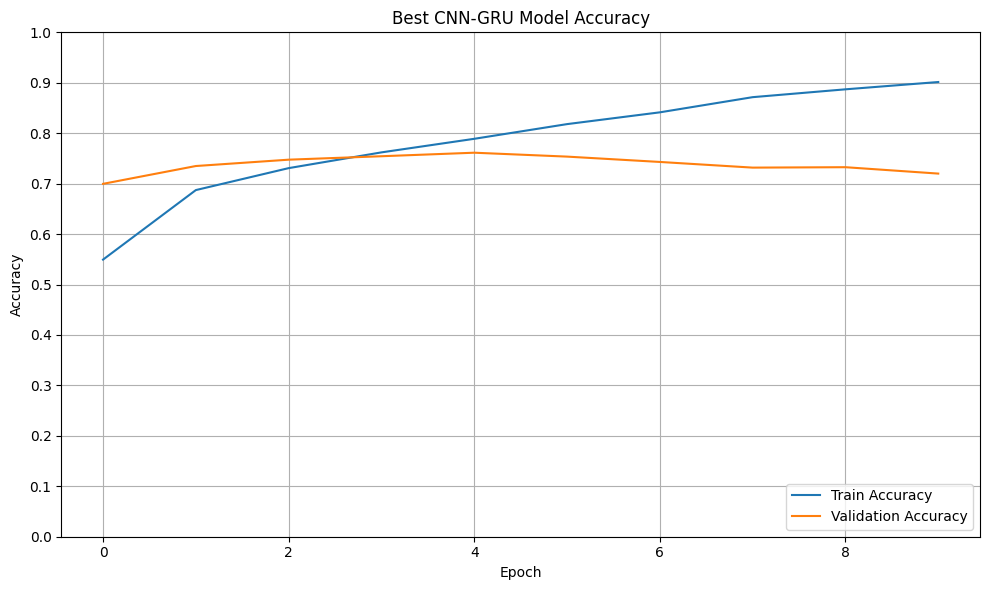

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(hist_cnn_gru.history['acc'], label='Train Accuracy')
plt.plot(hist_cnn_gru.history['val_acc'], label='Validation Accuracy')
plt.title('Best CNN-GRU Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path_best_cg = os.path.join(file_dir, 'best_cnn_gru_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path_best_cg)
print(f"Best CNN-GRU Accuracy plot saved to: {accuracy_plot_path_best_cg}")
plt.show()

Best CNN-GRU Loss plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_gru_loss_plot_w.png


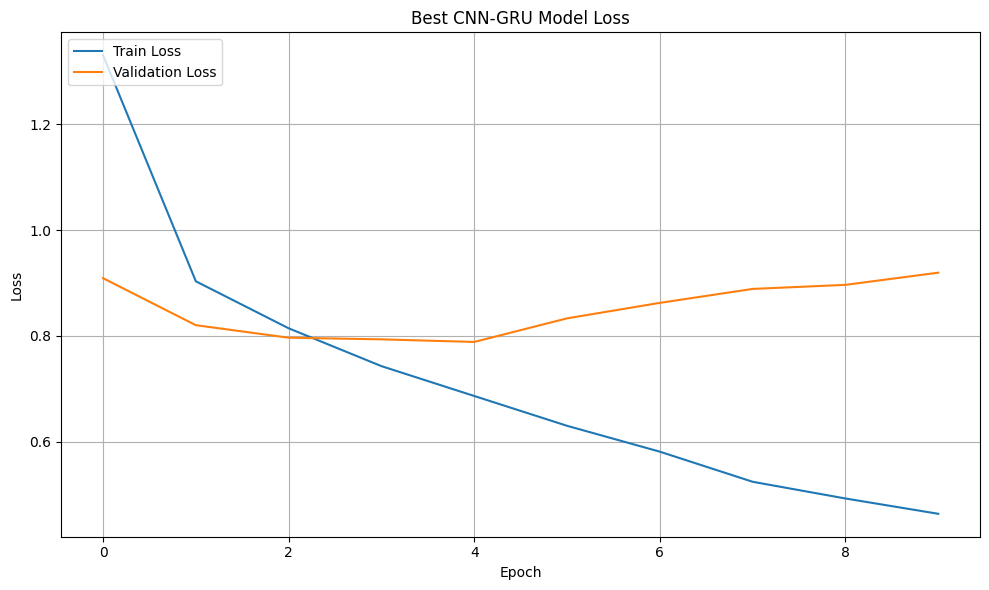

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(hist_cnn_gru.history['loss'], label='Train Loss')
plt.plot(hist_cnn_gru.history['val_loss'], label='Validation Loss')
plt.title('Best CNN-GRU Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path_best_cg = os.path.join(file_dir, 'best_cnn_gru_loss_plot_w.png')
plt.savefig(loss_plot_path_best_cg)
print(f"Best CNN-GRU Loss plot saved to: {loss_plot_path_best_cg}")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the training set for the best CNN-GRU model
y_pred_probs_train_best_cg = model_cnn_gru.predict(X_train)
# Convert probabilities to class labels
y_predict_best_cg_train = np.argmax(y_pred_probs_train_best_cg, axis=1)

# Compute confusion matrix for the best CNN-GRU model on training data
cm_best_cg_train = confusion_matrix(y_train, y_predict_best_cg_train)
print("Confusion Matrix for Train Data (Best CNN-GRU Model):")
print(cm_best_cg_train)

1750/1750 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step
Confusion Matrix for Train Data (Best CNN-GRU Model):
[[12531   182   141   106   733]
 [  182 10622   228   128   426]
 [  927   472 10553   106  1633]
 [    6    48     8  3264    10]
 [ 1632   405   501   240 10914]]


Best CNN-GRU Training Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_gru_train_confusion_matrix_w.png


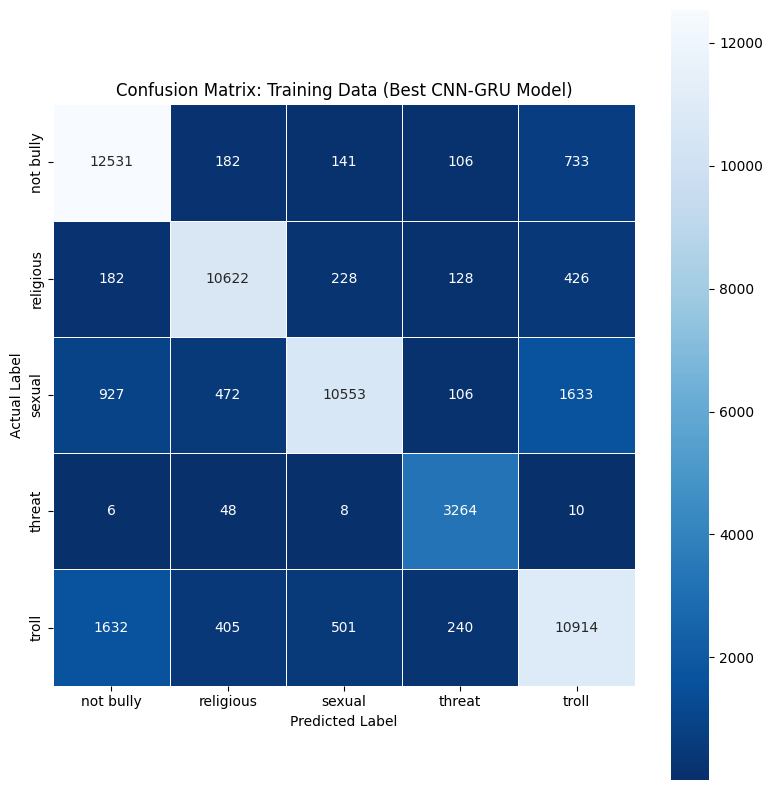

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_cg_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Training Data (Best CNN-GRU Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_best_cg = os.path.join(file_dir, 'best_cnn_gru_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_best_cg)
print(f"Best CNN-GRU Training Confusion Matrix plot saved to: {train_cm_plot_path_best_cg}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_cg_train = classification_report(y_train, y_predict_best_cg_train, target_names=classes)
print("Best CNN-GRU Train Report:\n", report_best_cg_train)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
train_report_path_best_cg = os.path.join(file_dir, 'best_cnn_gru_train_classification_report_w.txt')
with open(train_report_path_best_cg, 'w') as f:
    f.write("Best CNN-GRU Train Report:\n")
    f.write(report_best_cg_train)
print(f"Best CNN-GRU Training Classification Report saved to: {train_report_path_best_cg}")

Best CNN-GRU Train Report:
               precision    recall  f1-score   support

   not bully       0.82      0.92      0.87     13693
   religious       0.91      0.92      0.91     11586
      sexual       0.92      0.77      0.84     13691
      threat       0.85      0.98      0.91      3336
       troll       0.80      0.80      0.80     13692

    accuracy                           0.86     55998
   macro avg       0.86      0.88      0.86     55998
weighted avg       0.86      0.86      0.85     55998

Best CNN-GRU Training Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_gru_train_classification_report_w.txt


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the test set for the best CNN-GRU model
y_pred_probs_test_best_cg = model_cnn_gru.predict(X_test)
# Convert probabilities to class labels
y_predict_best_cg_test = np.argmax(y_pred_probs_test_best_cg, axis=1)

# Compute confusion matrix for the best CNN-GRU model on test data
cm_best_cg_test = confusion_matrix(y_test, y_predict_best_cg_test)
print("Confusion Matrix for Test Data (Best CNN-GRU Model):")
print(cm_best_cg_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Confusion Matrix for Test Data (Best CNN-GRU Model):
[[2378   78   70   58  350]
 [  66 2138   54   50  174]
 [ 236  178 1928   47  545]
 [  22   30   14  574   74]
 [ 436  155  155   98 2089]]


Best CNN-GRU Test Confusion Matrix plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_gru_test_confusion_matrix_w.png


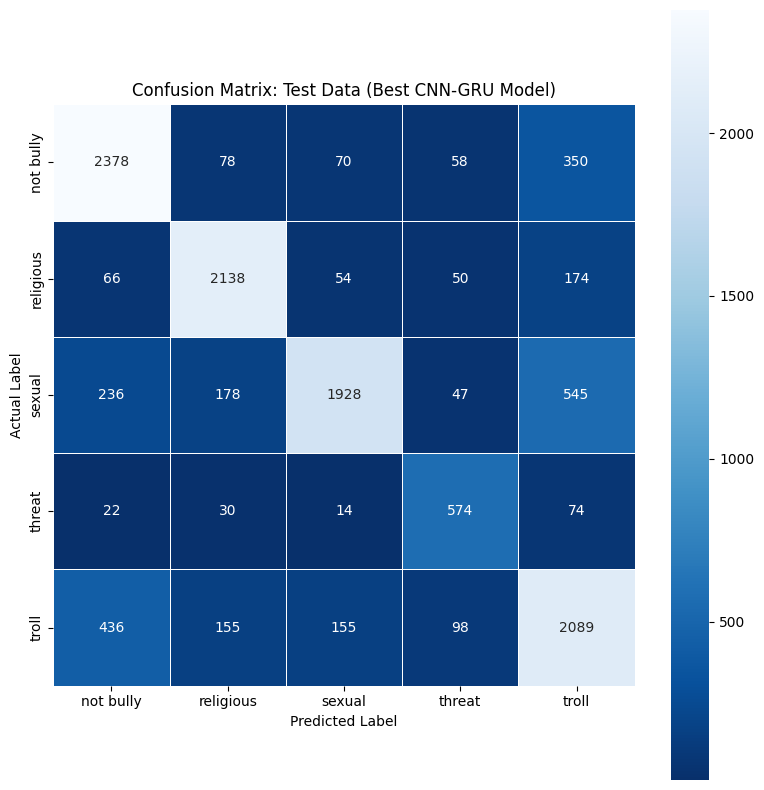

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_cg_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Test Data (Best CNN-GRU Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_best_cg = os.path.join(file_dir, 'best_cnn_gru_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_best_cg)
print(f"Best CNN-GRU Test Confusion Matrix plot saved to: {test_cm_plot_path_best_cg}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_cg_test = classification_report(y_test, y_predict_best_cg_test, target_names=classes)
print("Best CNN-GRU Test Report:\n", report_best_cg_test)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
test_report_path_best_cg = os.path.join(file_dir, 'best_cnn_gru_test_classification_report_w.txt')
with open(test_report_path_best_cg, 'w') as f:
    f.write("Best CNN-GRU Test Report:\n")
    f.write(report_best_cg_test)
print(f"Best CNN-GRU Test Classification Report saved to: {test_report_path_best_cg}")

Best CNN-GRU Test Report:
               precision    recall  f1-score   support

   not bully       0.76      0.81      0.78      2934
   religious       0.83      0.86      0.84      2482
      sexual       0.87      0.66      0.75      2934
      threat       0.69      0.80      0.74       714
       troll       0.65      0.71      0.68      2933

    accuracy                           0.76     11997
   macro avg       0.76      0.77      0.76     11997
weighted avg       0.77      0.76      0.76     11997

Best CNN-GRU Test Classification Report saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_gru_test_classification_report_w.txt


Best CNN-GRU ROC curve plot saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\best_cnn_gru_roc_curve_w.png


C:\Users\pciuc\AppData\Local\Temp\ipykernel_20964\3237572380.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('jet', n_classes)


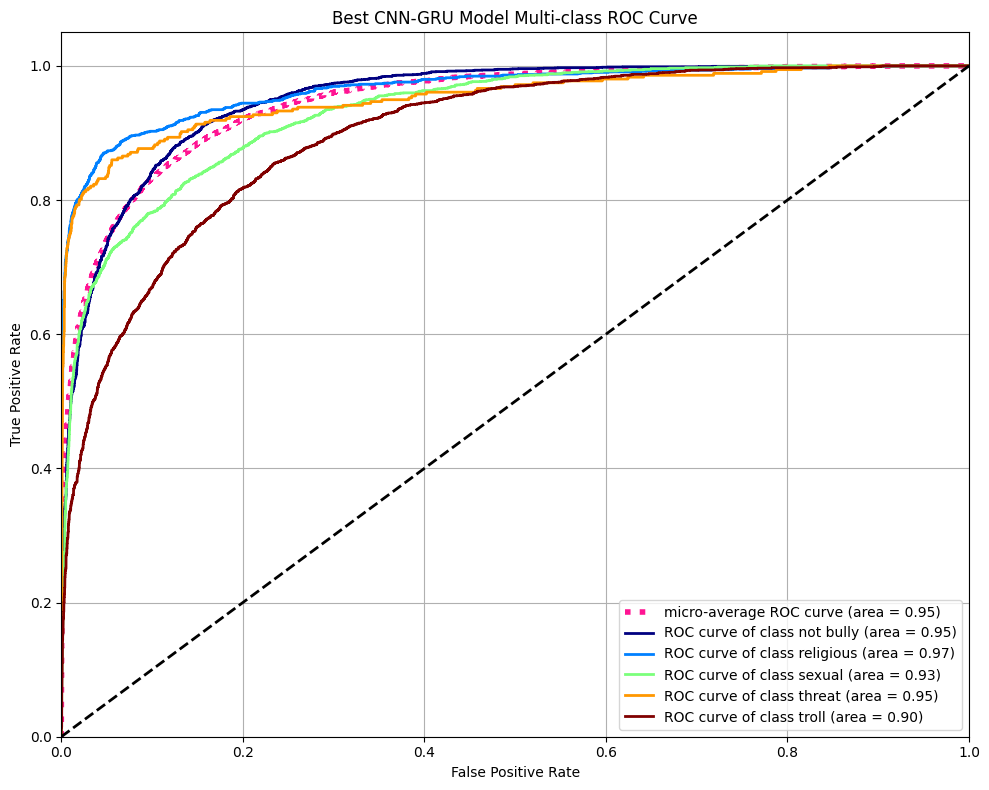

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical
import os

# Use OUTDIR for consistency
file_dir = OUTDIR

# Get the number of classes
n_classes = len(classes)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr_best_cg = dict()
tpr_best_cg = dict()
roc_auc_best_cg = dict()
for i in range(n_classes):
    fpr_best_cg[i], tpr_best_cg[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_best_cg[:, i])
    roc_auc_best_cg[i] = auc(fpr_best_cg[i], tpr_best_cg[i])

# Compute micro-average ROC curve and ROC area
fpr_micro_best_cg, tpr_micro_best_cg, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_best_cg.ravel())
roc_auc_micro_best_cg = auc(fpr_micro_best_cg, tpr_micro_best_cg)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_best_cg, tpr_micro_best_cg,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro_best_cg),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr_best_cg[i], tpr_best_cg[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(classes[i], roc_auc_best_cg[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Best CNN-GRU Model Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_best_cg = os.path.join(file_dir, 'best_cnn_gru_roc_curve_w.png')
plt.savefig(roc_plot_path_best_cg)
print(f"Best CNN-GRU ROC curve plot saved to: {roc_plot_path_best_cg}")
plt.show()

In [ ]:
import os

# Rebuild the CNN-GRU model architecture
# Ensure build_cnn_gru() is defined (it is in I5lOu7rI5Aqk)
model_cnn_gru = build_cnn_gru()

# Load the best weights saved during training from the correct checkpoint file
# The checkpoint name for cnn_gru is derived from the 'name' parameter in train_and_report function.
# It should be f"{EMB_ALGO}_{name}_s{SEED}.weights.h5"
# Given EMB_ALGO='word2vec' and SEED=42 for this run, the filename is 'word2vec_cnn_gru_s42.weights.h5'
weights_filename = f"{EMB_ALGO}_cnn_gru_s{SEED}.weights.h5"
model_cnn_gru.load_weights(weights_filename)

# Save the best CNN-GRU model with the '_w' suffix
model_save_path_best_cnn_gru = os.path.join(OUTDIR, 'CNN_GRU_model_best_w.keras')
model_cnn_gru.save(model_save_path_best_cnn_gru)
print(f"Best CNN-GRU model saved to: {model_save_path_best_cnn_gru}")

C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'masked_pool' (of type MaskedPool1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
C:\Users\pciuc\miniconda3\lib\site-packages\keras\src\saving\saving_lib.py:794: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 48 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Best CNN-GRU model saved to: D:\Mithila_CSE_30_A\CyberBulling dataset-20260806T082859Z-1-001\CyberBulling dataset\word2vec_final_updated\CNN_GRU_model_best_w.keras


CNN_LSTM_GRU

In [ ]:
from tensorflow.keras import regularizers

def build_cnn_lstm_gru():
    inp  = keras.Input(shape=(MAXLEN,), dtype="int32", name="tokens")
    mask = TokenMask(name="mask")(inp)
    x = layers.Embedding(len(vocab), EMB_DIM, weights=[embedding_matrix],
                         trainable=True, name="w2v_embedding")(inp)
    x = layers.SpatialDropout1D(DROP_EMB)(x)

    br = [layers.Conv1D(HYB_FILTERS, k, padding="same", activation="elu",
                        kernel_regularizer=regularizers.l2(L2), name=f"conv{k}")(x)
          for k in HYB_KERNELS]
    x = layers.Concatenate(name="conv_concat")(br)           # (None, 56, 256)

    x = layers.Bidirectional(
        layers.LSTM(128, return_sequences=True, recurrent_dropout=0.0),
        name="bilstm_1")(x, mask=mask)                       # (None, 56, 256)
    x = layers.Bidirectional(
        layers.GRU(64, return_sequences=True, recurrent_dropout=0.0),
        name="bigru_2")(x, mask=mask)                        # (None, 56, 128)

    h = MaskedPool1D(name="masked_pool")([x, mask])          # (None, 256)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_MID)(h)
    h = layers.Dense(HEAD_UNITS, activation="elu", kernel_regularizer=regularizers.l2(L2))(h)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(DROP_HEAD)(h)
    out = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(h)

    m = keras.Model(inp, out, name="cnn_lstm_gru")
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

reset_seeds()
model_cnn_lstm_gru = build_cnn_lstm_gru()
model_cnn_lstm_gru.summary()
hist_cnn_lstm_gru = train_and_report("cnn_lstm_gru", model_cnn_lstm_gru)

In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import os
from tensorflow.keras.losses import CategoricalCrossentropy # Import for manual loss calculation
from tensorflow.keras.utils import to_categorical # Import to_categorical

# Predict probabilities on the test set for the best CNN-LSTM-GRU model
y_pred_probs_test_best_eeg = model_cnn_lstm_gru.predict(X_test, verbose=0)
# Convert probabilities to class labels
y_predict_best_eeg_test = np.argmax(y_pred_probs_test_best_eeg, axis=1)

# Convert y_test to one-hot encoding for evaluate
y_test_one_hot = to_categorical(y_test, num_classes=NUM_CLASSES) # NEW LINE

loss_cnn_lstm_gru, accuracy_cnn_lstm_gru = model_cnn_lstm_gru.evaluate(X_test, y_test_one_hot, verbose=0) # MODIFIED LINE
macro_f1_cnn_lstm_gru = f1_score(y_test, y_predict_best_eeg_test, average='macro')

# Calculate loss manually using CategoricalCrossentropy and one-hot encoded y_test # NEW BLOCK
cce_loss_fn = CategoricalCrossentropy(from_logits=False) # from_logits=False because softmax activation is used
loss = cce_loss_fn(y_test_one_hot, y_pred_probs_test_best_eeg).numpy() # MODIFIED LINE to use y_test_one_hot

output_text = (
    f'Test Loss of Best CNN-LSTM-GRU Model: {loss:.4f}\n' + # MODIFIED to use `loss` variable
    f'Test Accuracy of Best CNN-LSTM-GRU Model: {accuracy_cnn_lstm_gru:.4f}\n' +
    f'Test Macro F1 Score of Best CNN-LSTM-GRU Model: {macro_f1_cnn_lstm_gru:.4f}'
)

print(output_text)

# Save the output to a text file
file_dir = OUTDIR # Use base_save_dir directly for consistency
output_report_path = os.path.join(file_dir, 'cnn_lstm_gru_test_evaluation_metrics_w.txt')
with open(output_report_path, 'w') as f:
    f.write(output_text)
print(f"CNN-LSTM-GRU test evaluation metrics saved to: {output_report_path}")

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation accuracy values
plt.figure(figsize=(10, 6))
plt.plot(hist_cnn_lstm_gru.history['acc'], label='Train Accuracy')
plt.plot(hist_cnn_lstm_gru.history['val_acc'], label='Validation Accuracy')
plt.title('CNN-LSTM-GRU Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([i / 10 for i in range(11)])
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
accuracy_plot_path_best_eeg = os.path.join(file_dir, 'best_cnn_lstm_gru_accuracy_plot_w.png')
plt.savefig(accuracy_plot_path_best_eeg)
print(f"Best CNN-LSTM-GRU Accuracy plot saved to: {accuracy_plot_path_best_eeg}")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Plot training & validation loss values
plt.figure(figsize=(10, 6))
plt.plot(hist_cnn_lstm_gru.history['loss'], label='Train Loss')
plt.plot(hist_cnn_lstm_gru.history['val_loss'], label='Validation Loss')
plt.title('CNN-LSTM-GRU Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()

# Save the plot to Google Drive
loss_plot_path_best_eeg = os.path.join(file_dir, 'best_cnn_lstm_gru_loss_plot_w.png')
plt.savefig(loss_plot_path_best_eeg)
print(f"Best CNN-LSTM-GRU Loss plot saved to: {loss_plot_path_best_eeg}")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the training set for the best CNN-LSTM-GRU model
y_pred_probs_train_best_eeg = model_cnn_lstm_gru.predict(X_train)
# Convert probabilities to class labels
y_predict_best_eeg_train = np.argmax(y_pred_probs_train_best_eeg, axis=1)

# Compute confusion matrix for the best CNN-LSTM-GRU model on training data
cm_best_eeg_train = confusion_matrix(y_train, y_predict_best_eeg_train)
print("Confusion Matrix for Train Data (Best CNN-LSTM-GRU Model):")
print(cm_best_eeg_train)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_eeg_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Training Data (Best CNN-LSTM-GRU Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
train_cm_plot_path_best_eeg = os.path.join(file_dir, 'best_cnn_lstm_gru_train_confusion_matrix_w.png')
plt.savefig(train_cm_plot_path_best_eeg)
print(f"Best CNN-LSTM-GRU Training Confusion Matrix plot saved to: {train_cm_plot_path_best_eeg}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_eeg_train = classification_report(y_train, y_predict_best_eeg_train, target_names=classes)
print("Best CNN-LSTM-GRU Train Report:\n", report_best_eeg_train)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
train_report_path_best_eeg = os.path.join(file_dir, 'best_cnn_lstm_gru_train_classification_report_w.txt')
with open(train_report_path_best_eeg, 'w') as f:
    f.write("Best CNN-LSTM-GRU Train Report:\n")
    f.write(report_best_eeg_train)
print(f"Best CNN-LSTM-GRU Training Classification Report saved to: {train_report_path_best_eeg}")

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict probabilities on the test set for the best CNN-LSTM-GRU model
y_pred_probs_test_best_eeg = model_cnn_lstm_gru.predict(X_test)
# Convert probabilities to class labels
y_predict_best_eeg_test = np.argmax(y_pred_probs_test_best_eeg, axis=1)

# Compute confusion matrix for the best CNN-LSTM-GRU model on test data
cm_best_eeg_test = confusion_matrix(y_test, y_predict_best_eeg_test)
print("Confusion Matrix for Test Data (Best CNN-LSTM-GRU Model):")
print(cm_best_eeg_test)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

plt.figure(figsize = (8,8))
sns.heatmap(cm_best_eeg_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r",
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix: Test Data (Best CNN-LSTM-GRU Model)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Save the plot to Google Drive
test_cm_plot_path_best_eeg = os.path.join(file_dir, 'best_cnn_lstm_gru_test_confusion_matrix_w.png')
plt.savefig(test_cm_plot_path_best_eeg)
print(f"Best CNN-LSTM-GRU Test Confusion Matrix plot saved to: {test_cm_plot_path_best_eeg}")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report_best_eeg_test = classification_report(y_test, y_predict_best_eeg_test, target_names=classes)
print("Best CNN-LSTM-GRU Test Report:\n", report_best_eeg_test)

# Save the report to Google Drive
import os
file_dir = OUTDIR # Use base_save_dir directly for consistency
test_report_path_best_eeg = os.path.join(file_dir, 'best_cnn_lstm_gru_test_classification_report_w.txt')
with open(test_report_path_best_eeg, 'w') as f:
    f.write("Best CNN-LSTM-GRU Test Report:\n")
    f.write(report_best_eeg_test)
print(f"Best CNN-LSTM-GRU Test Classification Report saved to: {test_report_path_best_eeg}")

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical
import os

# Use base_save_dir directly for consistency
file_dir = OUTDIR

# Get the number of classes
n_classes = len(classes)

# Convert y_test to one-hot encoding
y_test_one_hot = to_categorical(y_test, num_classes=n_classes)

# Compute ROC curve and ROC area for each class
fpr_best_eeg = dict()
tpr_best_eeg = dict()
roc_auc_best_eeg = dict()
for i in range(n_classes):
    fpr_best_eeg[i], tpr_best_eeg[i], _ = roc_curve(y_test_one_hot[:, i], y_pred_probs_test_best_eeg[:, i])
    roc_auc_best_eeg[i] = auc(fpr_best_eeg[i], tpr_best_eeg[i])

# Compute micro-average ROC curve and ROC area
fpr_micro_best_eeg, tpr_micro_best_eeg, _ = roc_curve(y_test_one_hot.ravel(), y_pred_probs_test_best_eeg.ravel())
roc_auc_micro_best_eeg = auc(fpr_micro_best_eeg, tpr_micro_best_eeg)

# Plot all ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_best_eeg, tpr_micro_best_eeg,
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc_micro_best_eeg),
         color='deeppink', linestyle=':', linewidth=4)

colors = plt.cm.get_cmap('jet', n_classes)
for i, color in zip(range(n_classes), colors(np.linspace(0, 1, n_classes))):
    plt.plot(fpr_best_eeg[i], tpr_best_eeg[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
                   ''.format(classes[i], roc_auc_best_eeg[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Best CNN-LSTM-GRU Model Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

# Save the plot
roc_plot_path_best_eeg = os.path.join(file_dir, 'best_cnn_lstm_gru_roc_curve_w.png')
plt.savefig(roc_plot_path_best_eeg)
print(f"Best CNN-LSTM-GRU ROC curve plot saved to: {roc_plot_path_best_eeg}")
plt.show()

In [ ]:
import os

# Save the best CNN-LSTM-GRU model with the '_w' suffix
model_save_path_best_cnn_lstm_gru = os.path.join(OUTDIR, 'CNN_LSTM_GRU_model_w.keras')
model_cnn_lstm_gru.save(model_save_path_best_cnn_lstm_gru)
print(f"Best CNN-LSTM-GRU model saved to: {model_save_path_best_cnn_lstm_gru}")

Results

In [ ]:
cmp = (pd.DataFrame(RESULTS).T.sort_values("macro_F1", ascending=False)
       .astype({"params": int, "epochs": int}).round(4))
print("evaluated on 8,764 unique test comments (duplicate rows removed)\n")
print(cmp.to_string())
cmp.to_csv(OUTDIR / "model_comparison.csv")

for name_key, model_obj in (("cnn", globals().get("model")), ("lstm", globals().get("model_lstm")),
                ("gru", globals().get("model_gru")),
                ("cnn_lstm", globals().get("model_cnn_lstm")),
                ("cnn_gru", globals().get("model_cnn_gru")),
                ("cnn_lstm_gru", globals().get("model_cnn_lstm_gru"))):
    if model_obj is not None:
        # Special handling for the initial 'cnn' model's weight file name
        if name_key == "cnn":
            weights_filename = "bangla_cnn.weights.h5" # This is the actual saved name
            save_name_prefix = "bangla_cnn" # Name for saving the full model
        else:
            weights_filename = f"{name_key}.weights.h5"
            save_name_prefix = name_key

        model_obj.load_weights(weights_filename)
        model_obj.save(OUTDIR / f"{save_name_prefix}.keras")
        print(f"saved {save_name_prefix}")

Accuracy Plot

In [ ]:
import numpy as np
import os
import re # Import re for regex

def get_history_value(history_obj, metric, default_value=np.nan, model_name="Unknown"):
    if isinstance(history_obj, tf.keras.callbacks.History) and metric in history_obj.history:
        return history_obj.history[metric][-1] * 100
    else:
        print(f"Warning: History object for {model_name} or metric '{metric}' not found. Setting to NaN.")
        return default_value

def get_macro_f1_value(model_tag_lower, base_dir, default_value=np.nan):
    """
    Reads the test evaluation metrics file for a given model and extracts the Macro F1 score.
    model_tag_lower: Lowercase identifier for the model (e.g., 'cnn', 'lstm').
    base_dir: The base directory where the metric files are saved.
    """
    if not base_dir:
        print(f"Warning: base_dir is not defined. Cannot retrieve Macro F1 for {model_tag_lower}.")
        return default_value

    file_name = f'{model_tag_lower}_test_evaluation_metrics_w.txt'
    file_path = os.path.join(base_dir, file_name)

    if not os.path.exists(file_path):
        print(f"Warning: Macro F1 file not found for {model_tag_lower} at {file_path}. Setting to NaN.")
        return default_value

    try:
        with open(file_path, 'r') as f:
            for line in f:
                if 'Test Macro F1 Score' in line:
                    # Use regex to find floating point number after "Score of Best X Model:"
                    match = re.search(r'Test Macro F1 Score of Best .* Model:\s*([0-9.]+)', line)
                    if match:
                        return float(match.group(1)) * 100 # Convert to percentage
    except Exception as e:
        print(f"Error reading Macro F1 from {file_path} for {model_tag_lower}: {e}. Setting to NaN.")

    return default_value

# Get OUTDIR for consistency
current_outdir = globals().get('OUTDIR')

model_accuracies = {
    'CNN': {
        'Train Accuracy': get_history_value(globals().get('history'), 'accuracy', model_name='CNN'),
        'Test Accuracy': get_history_value(globals().get('history'), 'val_accuracy', model_name='CNN'),
        'Macro F1': get_macro_f1_value('cnn', current_outdir)
    },
    'LSTM': {
        'Train Accuracy': get_history_value(globals().get('hist_lstm'), 'accuracy', model_name='LSTM'),
        'Test Accuracy': get_history_value(globals().get('hist_lstm'), 'val_accuracy', model_name='LSTM'),
        'Macro F1': get_macro_f1_value('lstm', current_outdir)
    },
    'GRU': {
        'Train Accuracy': get_history_value(globals().get('hist_gru'), 'accuracy', model_name='GRU'),
        'Test Accuracy': get_history_value(globals().get('hist_gru'), 'val_accuracy', model_name='GRU'),
        'Macro F1': get_macro_f1_value('gru', current_outdir)
    },
    'CNN-LSTM': {
        'Train Accuracy': get_history_value(globals().get('hist_cnn_lstm'), 'accuracy', model_name='CNN-LSTM'),
        'Test Accuracy': get_history_value(globals().get('hist_cnn_lstm'), 'val_accuracy', model_name='CNN-LSTM'),
        'Macro F1': get_macro_f1_value('cnn_lstm', current_outdir)
    },
    'CNN-GRU': {
        'Train Accuracy': get_history_value(globals().get('hist_cnn_gru'), 'accuracy', model_name='CNN-GRU'),
        'Test Accuracy': get_history_value(globals().get('hist_cnn_gru'), 'val_accuracy', model_name='CNN-GRU'),
        'Macro F1': get_macro_f1_value('cnn_gru', current_outdir)
    },
    'CNN-LSTM-GRU': {
        'Train Accuracy': get_history_value(globals().get('hist_cnn_lstm_gru'), 'accuracy', model_name='CNN-LSTM-GRU'),
        'Test Accuracy': get_history_value(globals().get('hist_cnn_lstm_gru'), 'val_accuracy', model_name='CNN-LSTM-GRU'),
        'Macro F1': get_macro_f1_value('cnn_lstm_gru', current_outdir)
    }
}

# Filter out models that did not have valid accuracy or F1 history
valid_model_accuracies = {
    k: v for k, v in model_accuracies.items()
    if not np.isnan(v.get('Train Accuracy', np.nan)) or
       not np.isnan(v.get('Test Accuracy', np.nan)) or
       not np.isnan(v.get('Macro F1', np.nan))
}

# Convert to a format suitable for pandas DataFrame
accuracy_data = {
    'Model': [name for name in valid_model_accuracies.keys()],
    'Train Accuracy': [data['Train Accuracy'] for data in valid_model_accuracies.values()],
    'Test Accuracy': [data['Test Accuracy'] for data in valid_model_accuracies.values()],
    'Macro F1': [data['Macro F1'] for data in valid_model_accuracies.values()]
}
dic = accuracy_data

In [ ]:
import pandas as pd

metrics_df = pd.DataFrame(dic)
print(metrics_df.to_string(index=False))
metrics_df.to_csv(OUTDIR / 'all_models_metrics.csv', index=False)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use OUTDIR consistently for saving plots
file_dir = OUTDIR

# Check if metrics_df exists and is not empty
if 'metrics_df' in globals() and not metrics_df.empty:
    test = sns.catplot(x="Model", y="Test Accuracy", data=metrics_df, kind="bar", palette="colorblind", legend=False)
    plt.title("Test Accuracy Plot")
    plt.xticks(rotation = 90)

    ax = test.facet_axis(0, 0)

    for i in ax.patches:
        ax.annotate(f'{i.get_height():.2f}', (i.get_x() + i.get_width() / 2., i.get_height()),
                    ha='center', va='center', xytext=(0, 9), textcoords='offset points')

    plt.tight_layout()
    plt.savefig(os.path.join(file_dir, 'all_models_test_accuracy_plot.png'))
    print(f"Test Accuracy Plot saved to: {os.path.join(file_dir, 'all_models_test_accuracy_plot.png')}")
    plt.show()
else:
    print("DataFrame 'metrics_df' for accuracy data is not available or empty. Cannot generate Test Accuracy Plot.")

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use OUTDIR consistently for saving plots
file_dir = OUTDIR

# Check if metrics_df exists and is not empty
if 'metrics_df' in globals() and not metrics_df.empty:
    train = sns.catplot(x="Model", y="Train Accuracy", data=metrics_df, kind="bar", palette="colorblind", legend=False)
    plt.title("Train Accuracy Plot")
    plt.xticks(rotation = 90)

    ax = train.facet_axis(0, 0)

    for i in ax.patches:
        ax.annotate(f'{i.get_height():.2f}', (i.get_x() + i.get_width() / 2., i.get_height()),
                    ha='center', va='center', xytext=(0, 9), textcoords='offset points')

    plt.tight_layout()
    plt.savefig(os.path.join(file_dir, 'all_models_train_accuracy_plot.png'))
    print(f"Train Accuracy Plot saved to: {os.path.join(file_dir, 'all_models_train_accuracy_plot.png')}")
    plt.show()
else:
    print("DataFrame 'metrics_df' for accuracy data is not available or empty. Cannot generate Train Accuracy Plot.")

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Use OUTDIR consistently for saving plots
file_dir = OUTDIR

# Check if metrics_df exists and is not empty
if 'metrics_df' in globals() and not metrics_df.empty:
    f1_plot = sns.catplot(x="Model", y="Macro F1", data=metrics_df, kind="bar", palette="viridis", legend=False)
    plt.title("Macro F1 Score Plot")
    plt.xticks(rotation=90)

    ax = f1_plot.facet_axis(0, 0)

    for i in ax.patches:
        ax.annotate(f'{i.get_height():.2f}', (i.get_x() + i.get_width() / 2., i.get_height()),
                    ha='center', va='center', xytext=(0, 9), textcoords='offset points')

    plt.tight_layout()
    plt.savefig(os.path.join(file_dir, 'all_models_macro_f1_plot.png'))
    print(f"Macro F1 Plot saved to: {os.path.join(file_dir, 'all_models_macro_f1_plot.png')}")
    plt.show()
else:
    print("DataFrame 'metrics_df' for Macro F1 data is not available or empty. Cannot generate Macro F1 Score Plot.")

In [ ]:
from tensorflow.keras.utils import to_categorical

# Define y_test_ohe if not already defined for test reports
if 'y_test_ohe' not in globals() or y_test_ohe.shape[1] != len(classes):
    y_test_ohe = to_categorical(y_test, num_classes=len(classes))

print("CNN Train Report:\n ", report_cnn_model1d_eval_train)
print("LSTM Train Report:\n ", report_best_lstm_train)
print("GRU Train Report:\n ", report_gru_train)
print("CNN-LSTM Train Report:\n ", report_best_cnn_lstm_train)
print("CNN-GRU Train Report:\n ", report_best_cg_train)
print("CNN-LSTM-GRU Train Report:\n ", report_best_eeg_train)

print("\nCNN Test Report:\n ", report_cnn_model1d_eval_test)
print("LSTM Test Report:\n ", report_best_lstm_test)
print("GRU Test Report:\n ", report_gru_test)
print("CNN-LSTM Test Report:\n ", report_best_cnn_lstm_test)
print("CNN-GRU Test Report:\n ", report_best_cg_test)
print("CNN-LSTM-GRU Test Report:\n ", report_best_eeg_test)


In [ ]:
import os
from tensorflow.keras.models import load_model
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.regularizers import l2

# Re-define and re-register custom layers if this cell is run independently
# This ensures that custom layers are known to Keras/TensorFlow when loading models
@tf.keras.utils.register_keras_serializable()
class TokenMask(layers.Layer):
    """1.0 for real tokens, 0.0 for <pad> (id 0)."""
    def call(self, ids):
        return tf.cast(tf.not_equal(ids, 0), tf.float32)
    def compute_output_shape(self, s):
        return s

@tf.keras.utils.register_keras_serializable()
class MaskedPool1D(layers.Layer):
    """Global max + mean over real timesteps only. Padding contributes nothing."""
    def call(self, inputs):
        x, mask = inputs                                  # (B,T,F), (B,T)
        m  = tf.expand_dims(tf.cast(mask, x.dtype), -1)    # (B,T,1)
        mx = tf.reduce_max(x - 1e9 * (1.0 - m), axis=1)
        av = tf.reduce_sum(x * m, axis=1) / tf.maximum(tf.reduce_sum(m, axis=1), 1e-9)
        return tf.concat([mx, av], axis=-1)
    def compute_output_shape(self, s):
        return (s[0][0], s[0][2] * 2)

# Ensure base_save_dir is defined
if 'base_save_dir' not in globals() or base_save_dir is None:
    print("Warning: 'base_save_dir' is not defined. Please define it in an earlier cell.")
    base_save_dir = './'

# Use OUTDIR consistently
save_dir = OUTDIR

models_loaded = {}

# Function to safely load a model
def safe_load_model(model_name, path):
    try:
        # custom_objects argument is crucial for loading models with custom layers
        model = load_model(path, custom_objects={'TokenMask': TokenMask, 'MaskedPool1D': MaskedPool1D})
        print(f"Successfully loaded {model_name} model from: {path}")
        return model
    except Exception as e:
        print(f"Could not load {model_name} model from {path}: {e}")
        return None

# Attempt to load each model with corrected filenames
CNN = safe_load_model('CNN', os.path.join(save_dir, 'bangla_cnn.keras')) # Corrected filename
LSTM = safe_load_model('LSTM', os.path.join(save_dir, 'lstm.keras'))     # Corrected filename
GRU = safe_load_model('GRU', os.path.join(save_dir, 'gru.keras'))         # Corrected filename
CNN_LSTM = safe_load_model('CNN-LSTM', os.path.join(save_dir, 'cnn_lstm.keras')) # Corrected filename
CNN_GRU = safe_load_model('CNN-GRU', os.path.join(save_dir, 'cnn_gru.keras'))   # Corrected filename
CNN_LSTM_GRU = safe_load_model('CNN-LSTM-GRU', os.path.join(save_dir, 'cnn_lstm_gru.keras')) # Corrected filename

# Populate models_loaded dictionary with successfully loaded models
if CNN is not None: models_loaded['CNN'] = CNN
if LSTM is not None: models_loaded['LSTM'] = LSTM
if GRU is not None: models_loaded['GRU'] = GRU
if CNN_LSTM is not None: models_loaded['CNN-LSTM'] = CNN_LSTM
if CNN_GRU is not None: models_loaded['CNN-GRU'] = CNN_GRU
if CNN_LSTM_GRU is not None: models_loaded['CNN-LSTM-GRU'] = CNN_LSTM_GRU

print(f"Successfully loaded models: {list(models_loaded.keys())}")

ROC-AUC Curve

In [ ]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np
import os

# Ensure n_classes is defined using the 'classes' list
n_classes = len(classes)

# Convert y_train to one-hot encoding if not already done
if 'y_train_ohe' not in globals() or y_train_ohe.shape[1] != n_classes:
    print("Creating y_train_ohe for ROC curve plotting.")
    y_train_ohe = to_categorical(y_train, num_classes=n_classes)

plt.figure(figsize=(12, 10))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier (AUC = 0.50)')

# Use models_loaded dictionary from the previous cell
if 'models_loaded' not in globals():
    print("Warning: 'models_loaded' dictionary not found. Please run the model loading cell for ROC curves.")
else:
    for model_name, model in models_loaded.items():
        try:
            # All models should use X_train for training ROC curves
            X_input = X_train

            y_score = model.predict(X_input)

            # Compute micro-averaged ROC curve and ROC area
            fpr, tpr, _ = roc_curve(y_train_ohe.ravel(), y_score.ravel())
            roc_auc = auc(fpr, tpr)

            plt.plot(fpr, tpr, lw=2, label=f'{model_name} (Micro-AUC = {roc_auc:.2f})')
        except Exception as e:
            print(f"Error generating ROC curve for {model_name}: {e}")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Micro-Averaged Receiver Operating Characteristic for Training Data')
plt.legend(loc="lower right")
plt.grid(True)

# Save the plot to OUTDIR consistently
file_dir = OUTDIR
plt.savefig(os.path.join(file_dir, 'all_models_train_roc_curve.png'))
print(f"Training ROC curve plot saved to: {os.path.join(file_dir, 'all_models_train_roc_curve.png')}")

plt.show()


In [ ]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np
import os

# Ensure n_classes is defined
n_classes = len(classes)

# Convert y_test to one-hot encoding if not already done
if 'y_test_ohe' not in globals() or y_test_ohe.shape[1] != n_classes:
    print("Creating y_test_ohe for ROC curve plotting.")
    y_test_ohe = to_categorical(y_test, num_classes=n_classes)

plt.figure(figsize=(12, 10))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier (AUC = 0.50)')

# Use models_loaded dictionary from the previous cell
if 'models_loaded' not in globals():
    print("Warning: 'models_loaded' dictionary not found. Please run the model loading cell for ROC curves.")
else:
    for model_name, model in models_loaded.items():
        try:
            # All models should use X_test for test ROC curves
            X_input = X_test

            y_score = model.predict(X_input)

            # Compute micro-averaged ROC curve and ROC area
            fpr, tpr, _ = roc_curve(y_test_ohe.ravel(), y_score.ravel())
            roc_auc = auc(fpr, tpr)

            plt.plot(fpr, tpr, lw=2, label=f'{model_name} (Micro-AUC = {roc_auc:.2f})')
        except Exception as e:
            print(f"Error generating ROC curve for {model_name}: {e}")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Micro-Averaged Receiver Operating Characteristic for Test Data')
plt.legend(loc="lower right")
plt.grid(True)

# Save the plot to OUTDIR consistently
file_dir = OUTDIR
plt.savefig(os.path.join(file_dir, 'all_models_test_roc_curve.png'))
print(f"Test ROC curve plot saved to: {os.path.join(file_dir, 'all_models_test_roc_curve.png')}")

plt.show()
